# AnalyticsPro - Phase 1


In [ ]:
print("AnalyticsPro Project Started!")
print("Phase 1: Data Analysis Pipeline")

AnalyticsPro Project Started!
Phase 1: Data Analysis Pipeline


In [ ]:
!pip install -q pandas numpy scipy scikit-learn matplotlib plotly openpyxl

In [ ]:
import pandas as pd
import numpy as np
import scipy
import sklearn
import matplotlib.pyplot as plt
import plotly.express as px
import openpyxl

print("All Phase 1 libraries are ready!")

All Phase 1 libraries are ready!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving student_academic_performance.csv to student_academic_performance.csv


In [ ]:
file_name = list(uploaded.keys())[0]

if file_name.lower().endswith(".csv"):
    df = pd.read_csv(file_name)

elif file_name.lower().endswith(".xlsx"):
    df = pd.read_excel(file_name)

else:
    raise ValueError("Please upload a CSV or Excel file.")

print("Dataset loaded successfully!")
print("File:", file_name)

Dataset loaded successfully!
File: student_academic_performance.csv


In [ ]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 7000
Number of Columns: 13


In [ ]:
df.head()

,Student ID,Gender,Race/Ethnicity,Parental Education,Lunch Type,Test Preparation,Study Time per Week,Daily Sleep Duration,Math Score,Reading Score,Writing Score,School Type,Internet Access
0,1,female,group B,some college,standard,False,12.4,5.4,62.0,76.0,65.0,public,True
1,2,male,group D,high school,standard,False,18.3,5.1,74.0,73.0,76.0,public,NaN
2,3,male,group B,bachelor degree,free/reduced,True,11.8,7.8,71.0,83.0,91.0,public,False
3,4,male,group E,high school,standard,False,NaN,7.3,83.0,73.0,52.0,public,True
4,5,female,group C,bachelor degree,standard,True,12.9,6.3,41.0,NaN,81.0,public,True


In [ ]:
print("Dataset Information")
print("===================")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Information
Rows: 7000
Columns: 13

Column Names:
['Student ID', 'Gender', 'Race/Ethnicity', 'Parental Education', 'Lunch Type', 'Test Preparation', 'Study Time per Week', 'Daily Sleep Duration', 'Math Score', 'Reading Score', 'Writing Score', 'School Type', 'Internet Access']

Data Types:
Student ID                int64
Gender                   object
Race/Ethnicity           object
Parental Education       object
Lunch Type               object
Test Preparation           bool
Study Time per Week     float64
Daily Sleep Duration    float64
Math Score              float64
Reading Score           float64
Writing Score           float64
School Type              object
Internet Access          object
dtype: object


In [ ]:
# Missing Value Analysis

missing_values = df.isnull().sum()

print("Missing Values in Each Column")
print("============================")

print(missing_values)

Missing Values in Each Column
Student ID                0
Gender                    0
Race/Ethnicity            0
Parental Education      700
Lunch Type              210
Test Preparation          0
Study Time per Week     630
Daily Sleep Duration    560
Math Score                0
Reading Score           490
Writing Score           350
School Type               0
Internet Access         280
dtype: int64


In [ ]:
# Missing Value Percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage")
print("========================")

print(missing_percentage)

Missing Value Percentage
Student ID               0.0
Gender                   0.0
Race/Ethnicity           0.0
Parental Education      10.0
Lunch Type               3.0
Test Preparation         0.0
Study Time per Week      9.0
Daily Sleep Duration     8.0
Math Score               0.0
Reading Score            7.0
Writing Score            5.0
School Type              0.0
Internet Access          4.0
dtype: float64


In [ ]:
# Duplicate Row Analysis

duplicate_count = df.duplicated().sum()

print("Duplicate Row Analysis")
print("======================")
print("Duplicate Rows:", duplicate_count)

Duplicate Row Analysis
Duplicate Rows: 0


In [ ]:
# Duplicate Percentage

duplicate_percentage = (duplicate_count / len(df)) * 100

print("Duplicate Percentage:", duplicate_percentage, "%")

Duplicate Percentage: 0.0 %


In [ ]:
duplicate_count = df.duplicated().sum()

print("Duplicate Rows:", duplicate_count)
print("Duplicate Percentage:", (duplicate_count / len(df)) * 100, "%")

Duplicate Rows: 0
Duplicate Percentage: 0.0 %


In [ ]:
# Create a copy of the original dataset

cleaned_df = df.copy()

print("Cleaned dataset created successfully!")
print("Original rows:", df.shape[0])
print("Cleaned rows:", cleaned_df.shape[0])

Cleaned dataset created successfully!
Original rows: 7000
Cleaned rows: 7000


In [ ]:
# Identify numerical and categorical columns

numerical_columns = cleaned_df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = cleaned_df.select_dtypes(include=["object", "bool"]).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['Student ID', 'Study Time per Week', 'Daily Sleep Duration', 'Math Score', 'Reading Score', 'Writing Score']

Categorical Columns:
['Gender', 'Race/Ethnicity', 'Parental Education', 'Lunch Type', 'Test Preparation', 'School Type', 'Internet Access']


In [ ]:
# Fill missing values in numerical columns using the median

for column in numerical_columns:
    cleaned_df[column] = cleaned_df[column].fillna(cleaned_df[column].median())

print("Missing numerical values handled successfully!")

Missing numerical values handled successfully!


In [ ]:
# Fill missing values in categorical columns using the mode

for column in categorical_columns:
    cleaned_df[column] = cleaned_df[column].fillna(cleaned_df[column].mode()[0])

print("Missing categorical values handled successfully!")

Missing categorical values handled successfully!


/tmp/ipykernel_1996/2255738439.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cleaned_df[column] = cleaned_df[column].fillna(cleaned_df[column].mode()[0])


In [ ]:
# Check remaining missing values

remaining_missing = cleaned_df.isnull().sum()

print("Remaining Missing Values")
print("========================")
print(remaining_missing)

Remaining Missing Values
Student ID              0
Gender                  0
Race/Ethnicity          0
Parental Education      0
Lunch Type              0
Test Preparation        0
Study Time per Week     0
Daily Sleep Duration    0
Math Score              0
Reading Score           0
Writing Score           0
School Type             0
Internet Access         0
dtype: int64


In [ ]:
# Check duplicate rows in the cleaned dataset

cleaned_duplicate_count = cleaned_df.duplicated().sum()

print("Duplicate Rows After Cleaning:", cleaned_duplicate_count)

Duplicate Rows After Cleaning: 0


In [ ]:
# Calculate duplicate percentage after cleaning

cleaned_duplicate_percentage = (
    cleaned_duplicate_count / len(cleaned_df)
) * 100

print("Duplicate Percentage After Cleaning:", cleaned_duplicate_percentage, "%")

Duplicate Percentage After Cleaning: 0.0 %


In [ ]:
# Statistical Summary of Numerical Data

print("Statistical Summary")
print("===================")

cleaned_df.describe()

Statistical Summary


,Student ID,Study Time per Week,Daily Sleep Duration,Math Score,Reading Score,Writing Score
count,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000
mean,3500.500000,9.657014,7.194100,69.476571,71.124714,70.487429
std,2020.870275,4.466320,1.263207,14.782909,13.325827,13.352877
min,1.000000,0.000000,3.000000,3.000000,21.000000,14.000000
25%,1750.750000,6.700000,6.400000,59.000000,63.000000,62.000000
50%,3500.500000,9.600000,7.200000,70.000000,71.000000,71.000000
75%,5250.250000,12.400000,8.000000,80.000000,80.000000,79.000000
max,7000.000000,26.100000,11.000000,100.000000,100.000000,100.000000


In [ ]:
# Analyze categorical columns

print("Categorical Data Distribution")
print("=============================")

for column in categorical_columns:
    print(f"\n{column}")
    print(cleaned_df[column].value_counts())

Categorical Data Distribution

Gender
Gender
female    3539
male      3461
Name: count, dtype: int64

Race/Ethnicity
Race/Ethnicity
group C    1820
group B    1482
group E    1405
group D    1297
group A     996
Name: count, dtype: int64

Parental Education
Parental Education
high school         2545
some college        1498
bachelor degree     1262
associate degree    1101
master degree        594
Name: count, dtype: int64

Lunch Type
Lunch Type
standard        4749
free/reduced    2251
Name: count, dtype: int64

Test Preparation
Test Preparation
False    3941
True     3059
Name: count, dtype: int64

School Type
School Type
public           4837
private          1480
international     683
Name: count, dtype: int64

Internet Access
Internet Access
True     6136
False     864
Name: count, dtype: int64


In [ ]:
# Numerical Distribution Summary

analysis_columns = [
    "Study Time per Week",
    "Daily Sleep Duration",
    "Math Score",
    "Reading Score",
    "Writing Score"
]

print("Numerical Distribution Summary")
print("==============================")

for column in analysis_columns:
    print(f"\n{column}")
    print("Mean:", round(cleaned_df[column].mean(), 2))
    print("Median:", round(cleaned_df[column].median(), 2))
    print("Minimum:", cleaned_df[column].min())
    print("Maximum:", cleaned_df[column].max())

Numerical Distribution Summary

Study Time per Week
Mean: 9.66
Median: 9.6
Minimum: 0.0
Maximum: 26.1

Daily Sleep Duration
Mean: 7.19
Median: 7.2
Minimum: 3.0
Maximum: 11.0

Math Score
Mean: 69.48
Median: 70.0
Minimum: 3.0
Maximum: 100.0

Reading Score
Mean: 71.12
Median: 71.0
Minimum: 21.0
Maximum: 100.0

Writing Score
Mean: 70.49
Median: 71.0
Minimum: 14.0
Maximum: 100.0


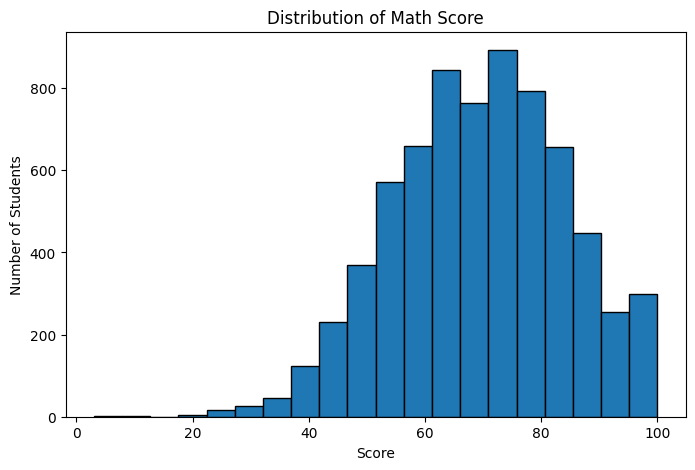

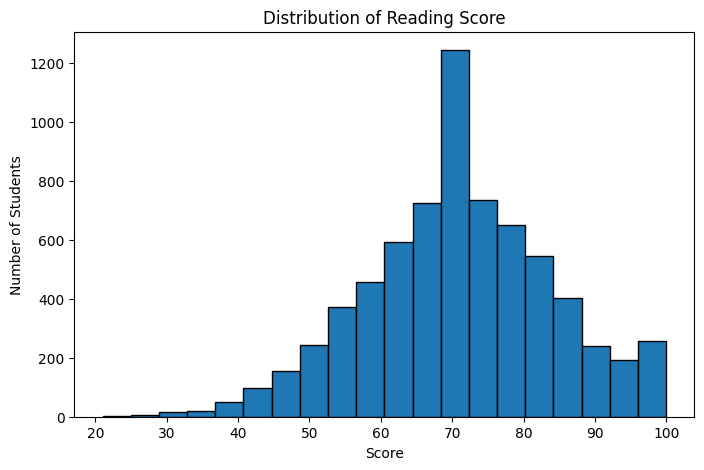

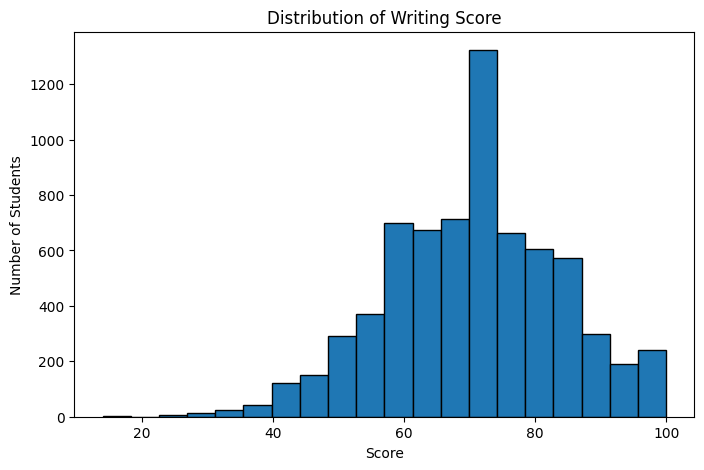

In [ ]:
# Score Distribution Analysis

score_columns = [
    "Math Score",
    "Reading Score",
    "Writing Score"
]

for column in score_columns:
    plt.figure(figsize=(8, 5))

    plt.hist(cleaned_df[column], bins=20, edgecolor="black")

    plt.title(f"Distribution of {column}")
    plt.xlabel("Score")
    plt.ylabel("Number of Students")

    plt.show()

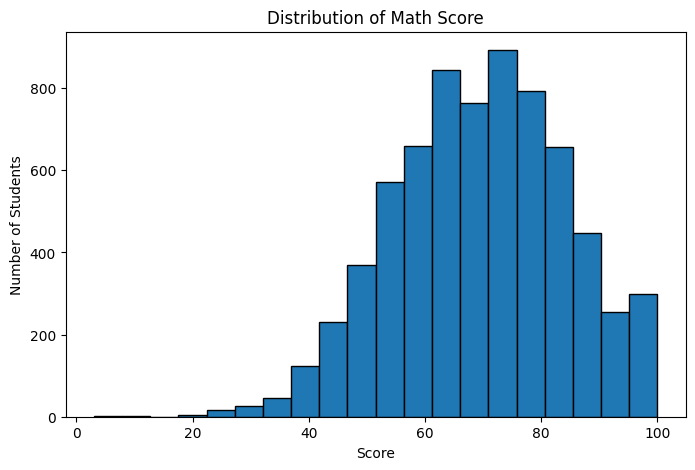

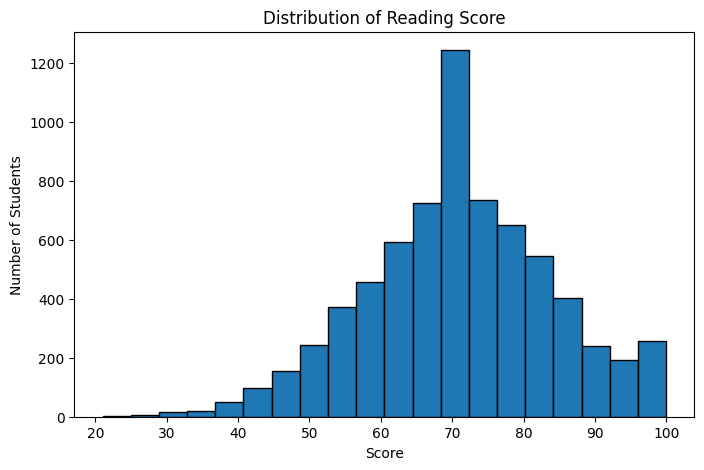

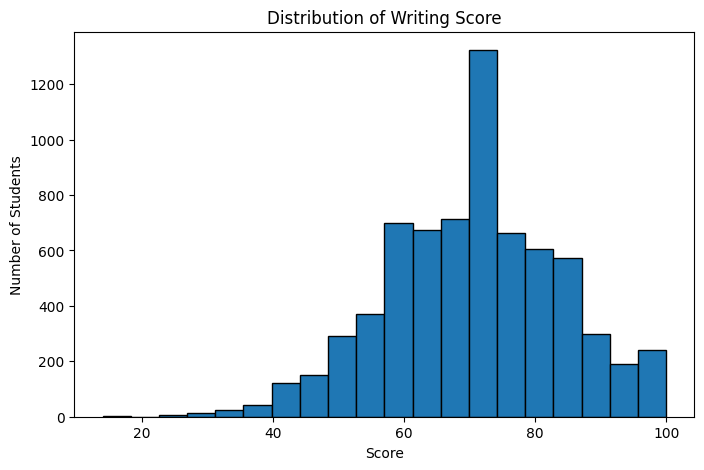

In [ ]:
# Score Distribution Analysis

score_columns = [
    "Math Score",
    "Reading Score",
    "Writing Score"
]

for column in score_columns:
    plt.figure(figsize=(8, 5))

    plt.hist(cleaned_df[column], bins=20, edgecolor="black")

    plt.title(f"Distribution of {column}")
    plt.xlabel("Score")
    plt.ylabel("Number of Students")

    plt.show()

Average Scores
Math Score       69.476571
Reading Score    71.124714
Writing Score    70.487429
dtype: float64


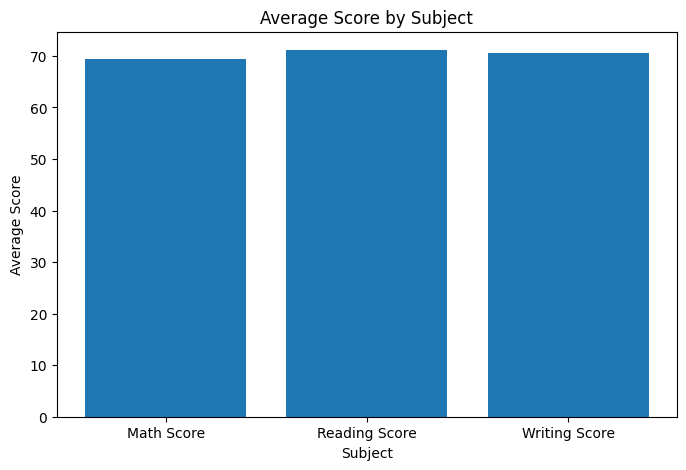

In [ ]:
# Average Score Comparison

average_scores = cleaned_df[score_columns].mean()

print("Average Scores")
print("==============")
print(average_scores)

plt.figure(figsize=(8, 5))

plt.bar(average_scores.index, average_scores.values)

plt.title("Average Score by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Score")

plt.show()

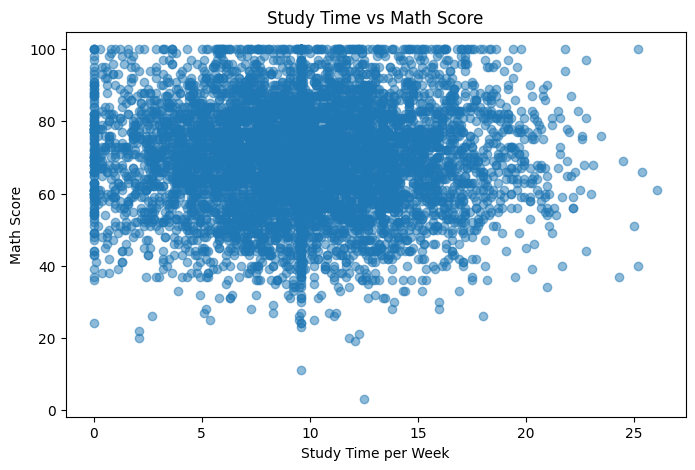

In [ ]:
# Study Time vs Math Score

plt.figure(figsize=(8, 5))

plt.scatter(
    cleaned_df["Study Time per Week"],
    cleaned_df["Math Score"],
    alpha=0.5
)

plt.title("Study Time vs Math Score")
plt.xlabel("Study Time per Week")
plt.ylabel("Math Score")

plt.show()

In [ ]:
# Calculate Overall Score

cleaned_df["Average Score"] = cleaned_df[
    ["Math Score", "Reading Score", "Writing Score"]
].mean(axis=1)

print("Average Score column created successfully!")
print(cleaned_df["Average Score"].head())

Average Score column created successfully!
0    67.666667
1    74.333333
2    81.666667
3    69.333333
4    64.333333
Name: Average Score, dtype: float64


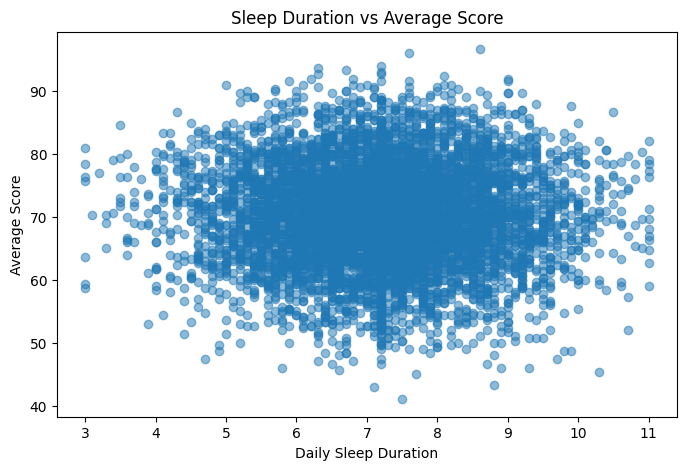

In [ ]:
# Sleep Duration vs Average Score

plt.figure(figsize=(8, 5))

plt.scatter(
    cleaned_df["Daily Sleep Duration"],
    cleaned_df["Average Score"],
    alpha=0.5
)

plt.title("Sleep Duration vs Average Score")
plt.xlabel("Daily Sleep Duration")
plt.ylabel("Average Score")

plt.show()

Average Score by Test Preparation
Test Preparation
False    70.299670
True     70.444372
Name: Average Score, dtype: float64


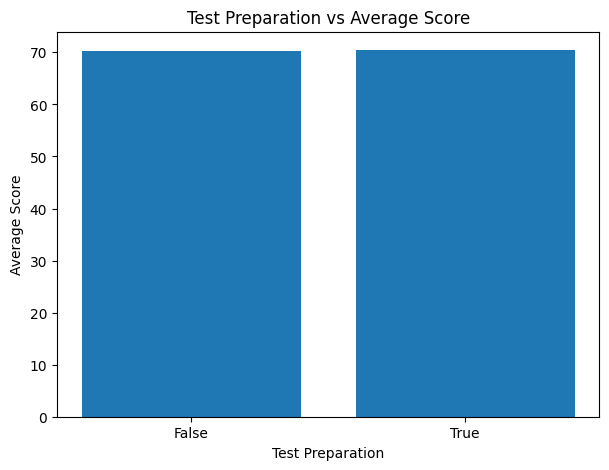

In [ ]:
# Test Preparation vs Average Score

test_prep_analysis = cleaned_df.groupby(
    "Test Preparation"
)["Average Score"].mean()

print("Average Score by Test Preparation")
print("=================================")
print(test_prep_analysis)

plt.figure(figsize=(7, 5))

plt.bar(
    test_prep_analysis.index.astype(str),
    test_prep_analysis.values
)

plt.title("Test Preparation vs Average Score")
plt.xlabel("Test Preparation")
plt.ylabel("Average Score")

plt.show()

Average Score by Lunch Type
Lunch Type
free/reduced    70.313935
standard        70.386116
Name: Average Score, dtype: float64


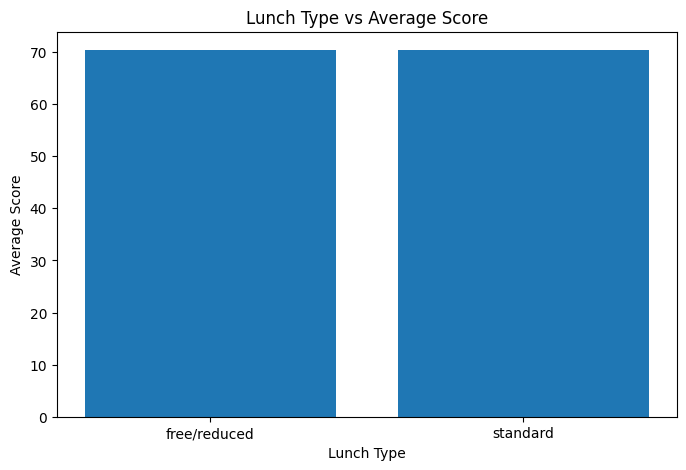

In [ ]:
# Lunch Type vs Average Score

lunch_analysis = cleaned_df.groupby(
    "Lunch Type"
)["Average Score"].mean()

print("Average Score by Lunch Type")
print("===========================")
print(lunch_analysis)

plt.figure(figsize=(8, 5))

plt.bar(
    lunch_analysis.index,
    lunch_analysis.values
)

plt.title("Lunch Type vs Average Score")
plt.xlabel("Lunch Type")
plt.ylabel("Average Score")

plt.show()

Average Score by School Type
School Type
international    70.493899
private          70.212387
public           70.390462
Name: Average Score, dtype: float64


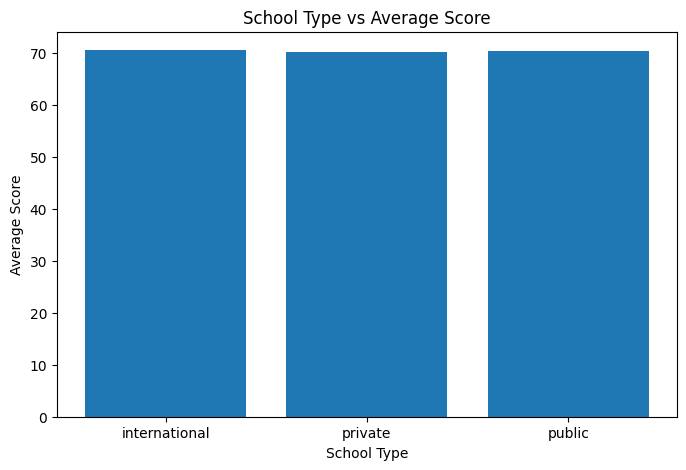

In [ ]:
# School Type vs Average Score

school_analysis = cleaned_df.groupby(
    "School Type"
)["Average Score"].mean()

print("Average Score by School Type")
print("============================")
print(school_analysis)

plt.figure(figsize=(8, 5))

plt.bar(
    school_analysis.index,
    school_analysis.values
)

plt.title("School Type vs Average Score")
plt.xlabel("School Type")
plt.ylabel("Average Score")

plt.show()

Average Score by Parental Education
Parental Education
bachelor degree     70.711041
some college        70.507788
associate degree    70.270360
high school         70.203798
master degree       70.111111
Name: Average Score, dtype: float64


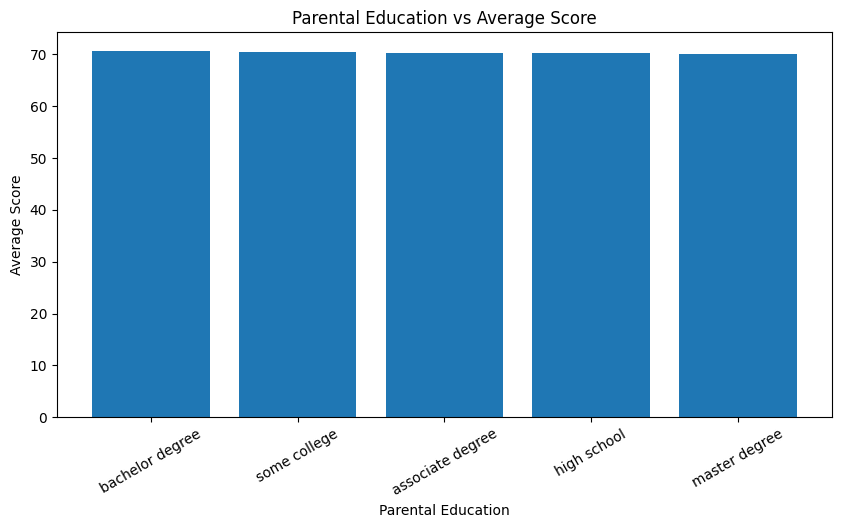

In [ ]:
# Parental Education vs Average Score

parent_education_analysis = cleaned_df.groupby(
    "Parental Education"
)["Average Score"].mean().sort_values(ascending=False)

print("Average Score by Parental Education")
print("===================================")
print(parent_education_analysis)

plt.figure(figsize=(10, 5))

plt.bar(
    parent_education_analysis.index,
    parent_education_analysis.values
)

plt.title("Parental Education vs Average Score")
plt.xlabel("Parental Education")
plt.ylabel("Average Score")

plt.xticks(rotation=30)

plt.show()

Average Score by Internet Access
Internet Access
False    70.393133
True     70.358648
Name: Average Score, dtype: float64


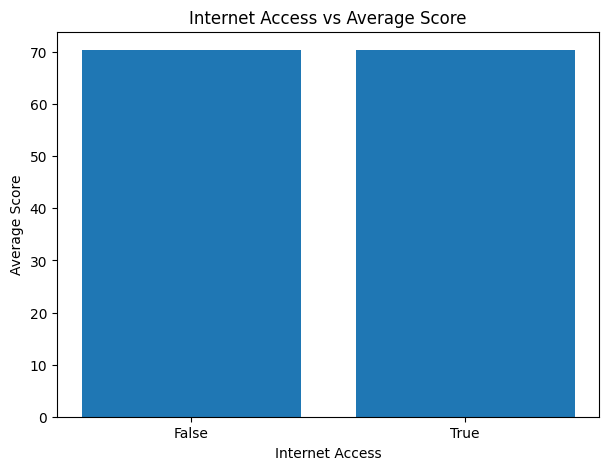

In [ ]:
# Internet Access vs Average Score

internet_analysis = cleaned_df.groupby(
    "Internet Access"
)["Average Score"].mean()

print("Average Score by Internet Access")
print("================================")
print(internet_analysis)

plt.figure(figsize=(7, 5))

plt.bar(
    internet_analysis.index.astype(str),
    internet_analysis.values
)

plt.title("Internet Access vs Average Score")
plt.xlabel("Internet Access")
plt.ylabel("Average Score")

plt.show()

In [ ]:
# Correlation Analysis

correlation_columns = [
    "Study Time per Week",
    "Daily Sleep Duration",
    "Math Score",
    "Reading Score",
    "Writing Score",
    "Average Score"
]

correlation_matrix = cleaned_df[
    correlation_columns
].corr()

print("Correlation Matrix")
print("==================")
print(correlation_matrix.round(2))

Correlation Matrix
                      Study Time per Week  Daily Sleep Duration  Math Score  \
Study Time per Week                  1.00                 -0.01        0.01   
Daily Sleep Duration                -0.01                  1.00       -0.01   
Math Score                           0.01                 -0.01        1.00   
Reading Score                       -0.01                  0.00        0.01   
Writing Score                       -0.02                 -0.01       -0.01   
Average Score                       -0.01                 -0.01        0.61   

                      Reading Score  Writing Score  Average Score  
Study Time per Week           -0.01          -0.02          -0.01  
Daily Sleep Duration           0.00          -0.01          -0.01  
Math Score                     0.01          -0.01           0.61  
Reading Score                  1.00           0.01           0.56  
Writing Score                  0.01           1.00           0.56  
Average Score      

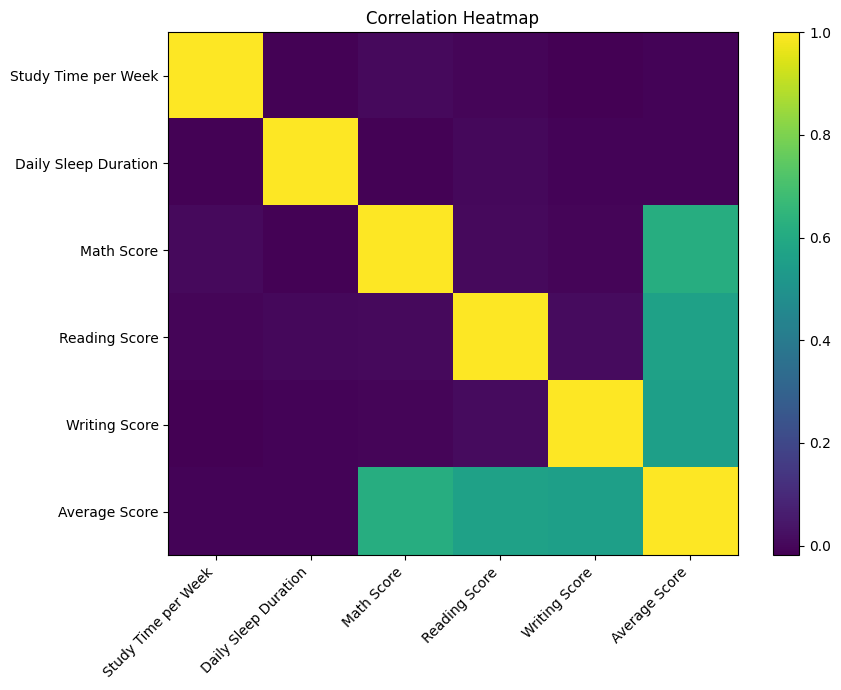

In [ ]:
# Correlation Heatmap

plt.figure(figsize=(9, 7))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.colorbar()

plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_columns)),
    correlation_columns
)

plt.title("Correlation Heatmap")

plt.tight_layout()

plt.show()

In [ ]:
# Basic EDA Insights

highest_average_subject = average_scores.idxmax()
highest_average_value = average_scores.max()

lowest_average_subject = average_scores.idxmin()
lowest_average_value = average_scores.min()

print("EDA Insights")
print("============")

print(
    f"Highest average subject: "
    f"{highest_average_subject} ({highest_average_value:.2f})"
)

print(
    f"Lowest average subject: "
    f"{lowest_average_subject} ({lowest_average_value:.2f})"
)

print(
    f"Average overall student score: "
    f"{cleaned_df['Average Score'].mean():.2f}"
)

print(
    f"Average study time per week: "
    f"{cleaned_df['Study Time per Week'].mean():.2f} hours"
)

print(
    f"Average daily sleep duration: "
    f"{cleaned_df['Daily Sleep Duration'].mean():.2f} hours"
)

EDA Insights
Highest average subject: Reading Score (71.12)
Lowest average subject: Math Score (69.48)
Average overall student score: 70.36
Average study time per week: 9.66 hours
Average daily sleep duration: 7.19 hours


In [ ]:
# EDA Summary

print("AnalyticsPro - EDA Summary")
print("==========================")

print("Dataset Size:", cleaned_df.shape)

print(
    "Average Math Score:",
    round(cleaned_df["Math Score"].mean(), 2)
)

print(
    "Average Reading Score:",
    round(cleaned_df["Reading Score"].mean(), 2)
)

print(
    "Average Writing Score:",
    round(cleaned_df["Writing Score"].mean(), 2)
)

print(
    "Average Overall Score:",
    round(cleaned_df["Average Score"].mean(), 2)
)

print(
    "Average Study Time:",
    round(cleaned_df["Study Time per Week"].mean(), 2)
)

print(
    "Average Sleep Duration:",
    round(cleaned_df["Daily Sleep Duration"].mean(), 2)
)

print(
    "Highest Average Subject:",
    average_scores.idxmax()
)

print(
    "Lowest Average Subject:",
    average_scores.idxmin()
)

AnalyticsPro - EDA Summary
Dataset Size: (7000, 14)
Average Math Score: 69.48
Average Reading Score: 71.12
Average Writing Score: 70.49
Average Overall Score: 70.36
Average Study Time: 9.66
Average Sleep Duration: 7.19
Highest Average Subject: Reading Score
Lowest Average Subject: Math Score


In [ ]:
# AnalyticsPro - Data Visualization
# Step 1: Identify numerical and categorical columns

visual_numerical_columns = cleaned_df.select_dtypes(
    include=np.number
).columns.tolist()

visual_categorical_columns = cleaned_df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Remove ID-like columns from visualization
id_columns = [
    col for col in visual_numerical_columns
    if "id" in col.lower()
]

visual_numerical_columns = [
    col for col in visual_numerical_columns
    if col not in id_columns
]

print("Numerical Columns for Visualization:")
print(visual_numerical_columns)

print("\nCategorical Columns for Visualization:")
print(visual_categorical_columns)

Numerical Columns for Visualization:
['Study Time per Week', 'Daily Sleep Duration', 'Math Score', 'Reading Score', 'Writing Score', 'Average Score']

Categorical Columns for Visualization:
['Gender', 'Race/Ethnicity', 'Parental Education', 'Lunch Type', 'Test Preparation', 'School Type', 'Internet Access']


Numerical Column Distributions


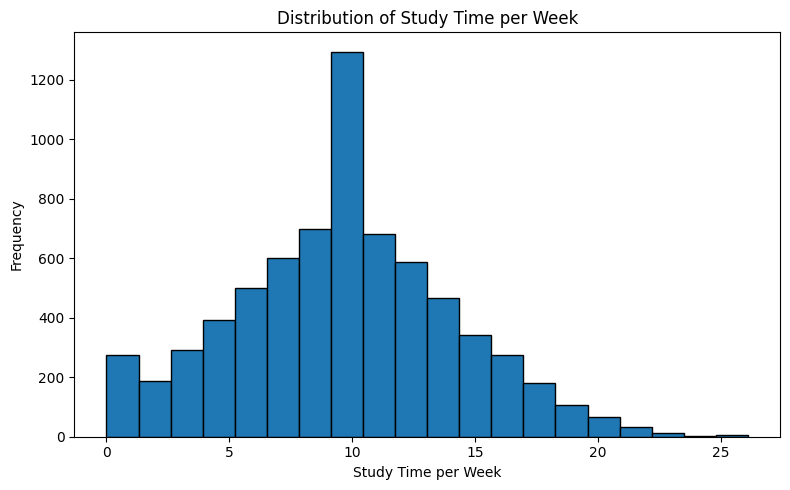

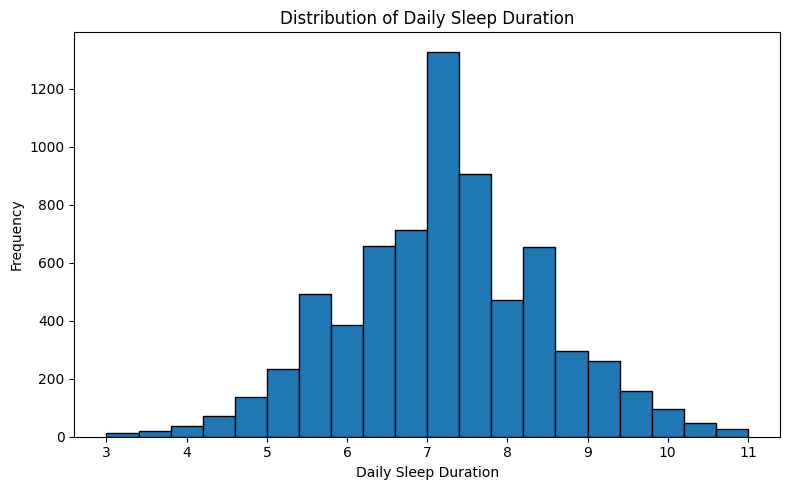

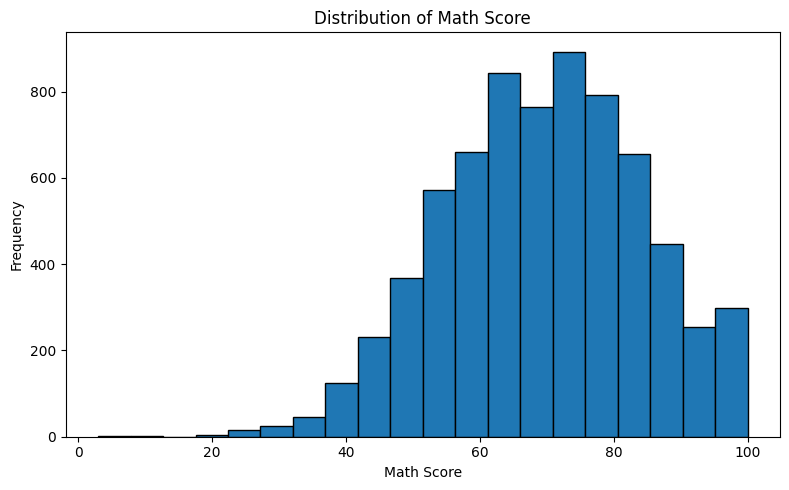

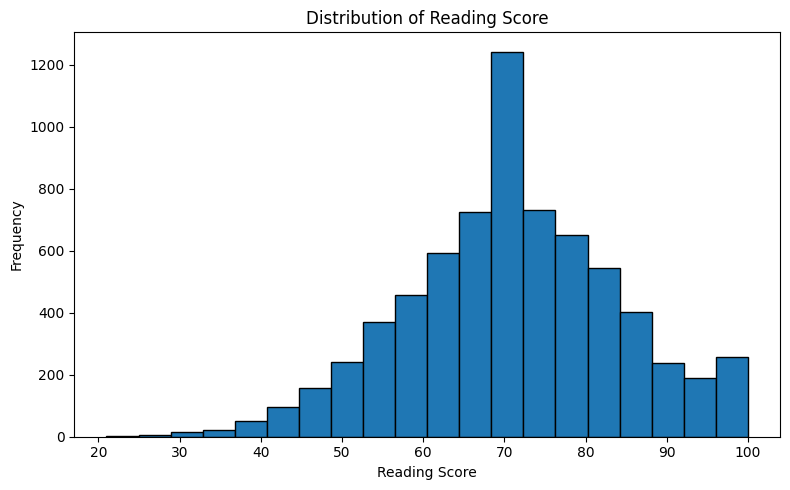

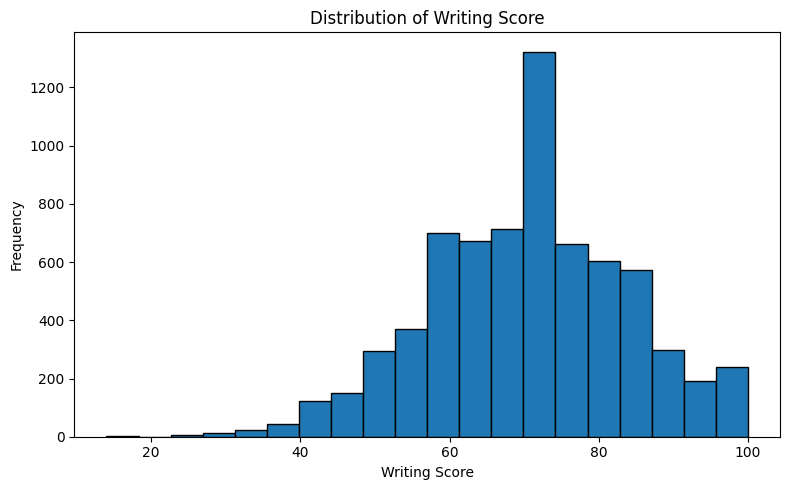

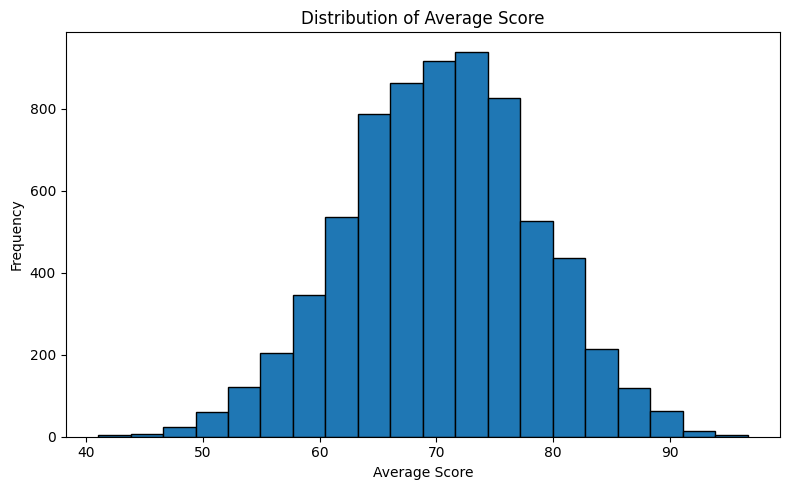

In [ ]:
# Step 2: Numerical column distributions

print("Numerical Column Distributions")
print("==============================")

for column in visual_numerical_columns:

    plt.figure(figsize=(8, 5))

    plt.hist(
        cleaned_df[column].dropna(),
        bins=20,
        edgecolor="black"
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

Numerical Column Boxplots


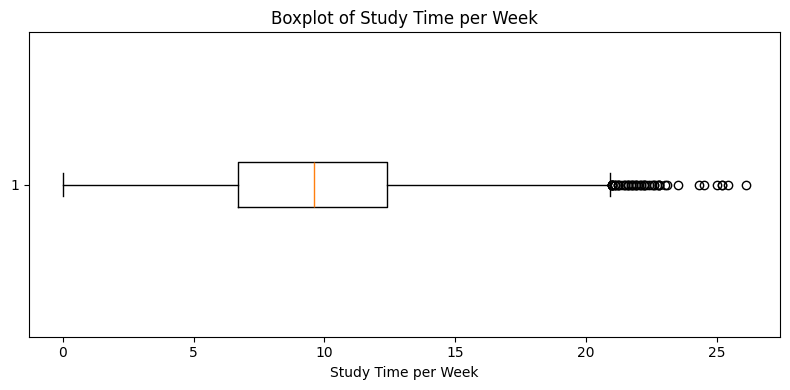

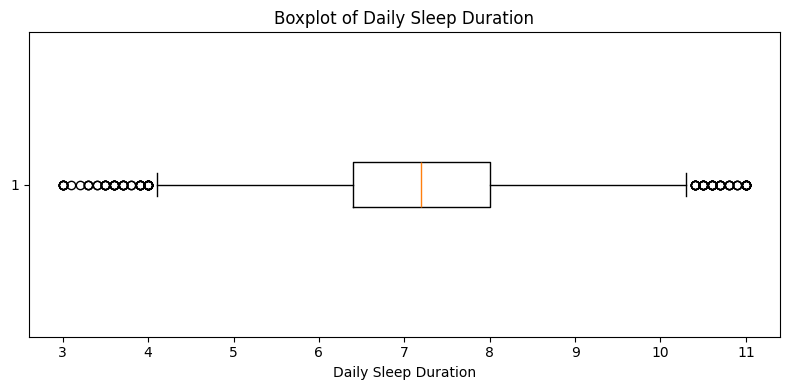

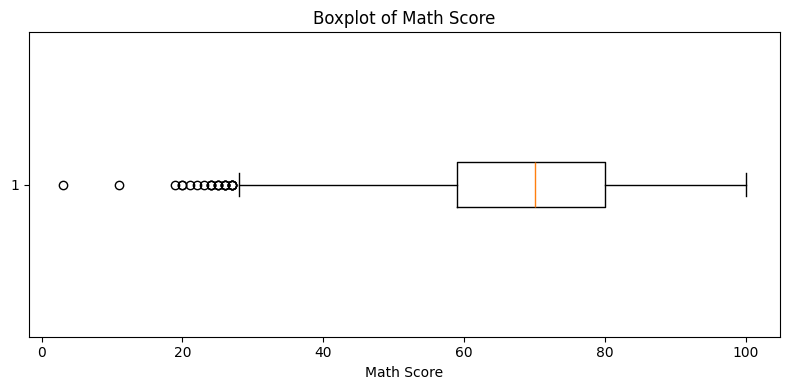

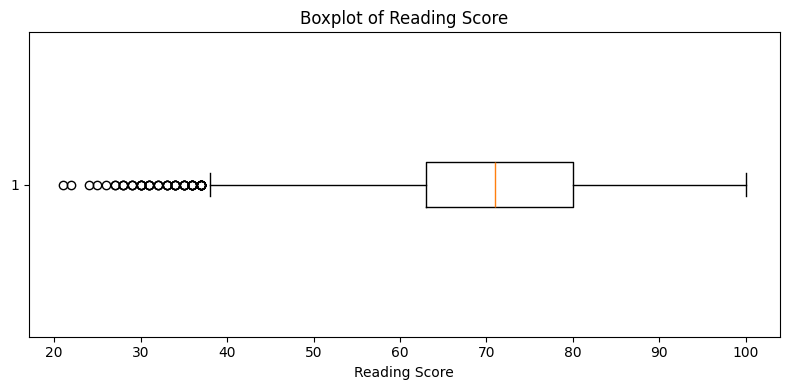

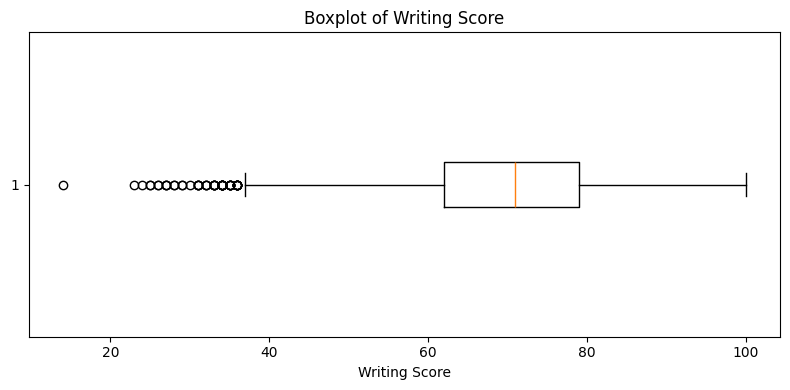

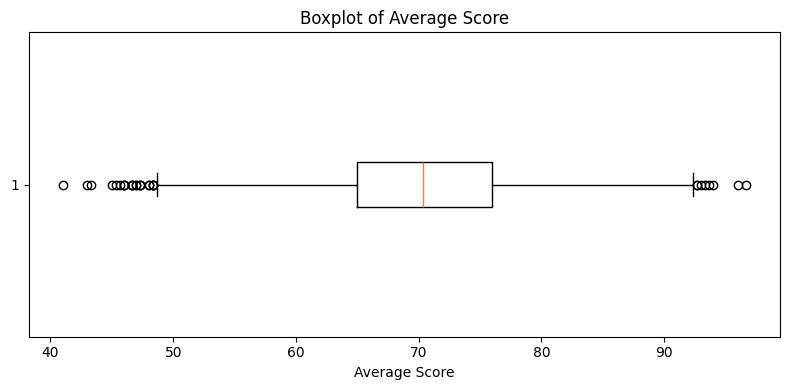

In [ ]:
# Step 3: Boxplots for numerical columns

print("Numerical Column Boxplots")
print("=========================")

for column in visual_numerical_columns:

    plt.figure(figsize=(8, 4))

    plt.boxplot(
        cleaned_df[column].dropna(),
        vert=False
    )

    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)

    plt.tight_layout()
    plt.show()

Categorical Column Distributions


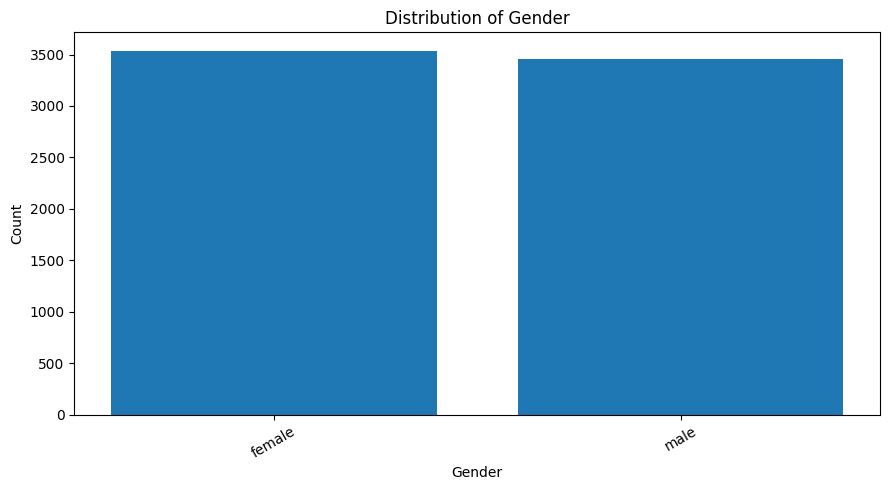

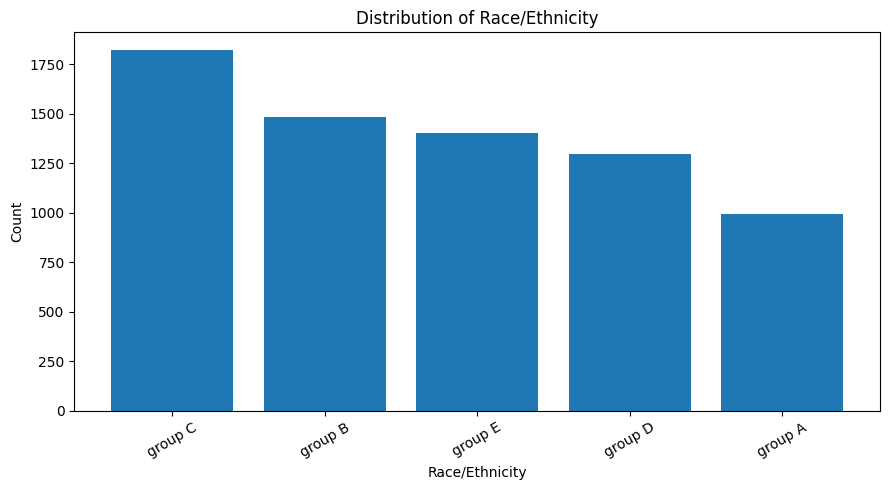

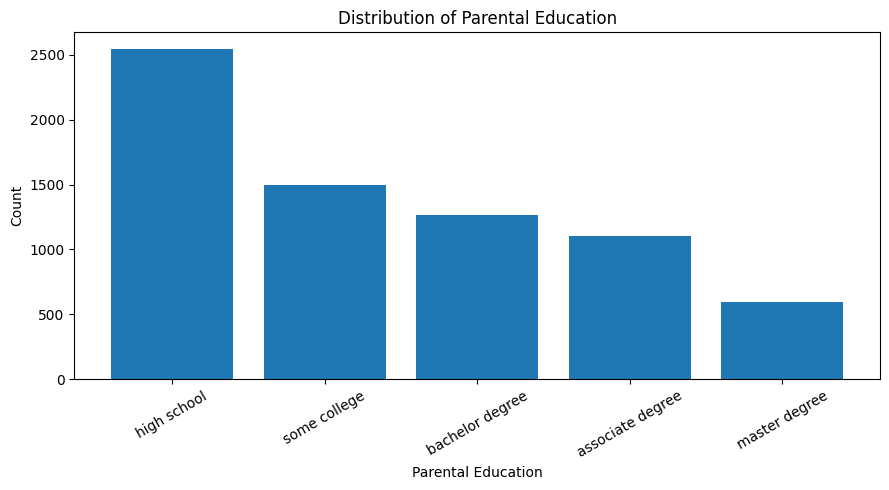

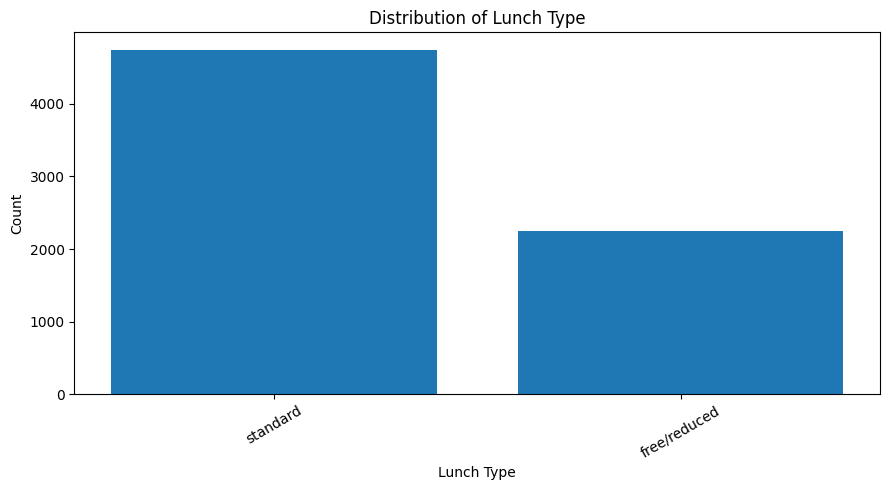

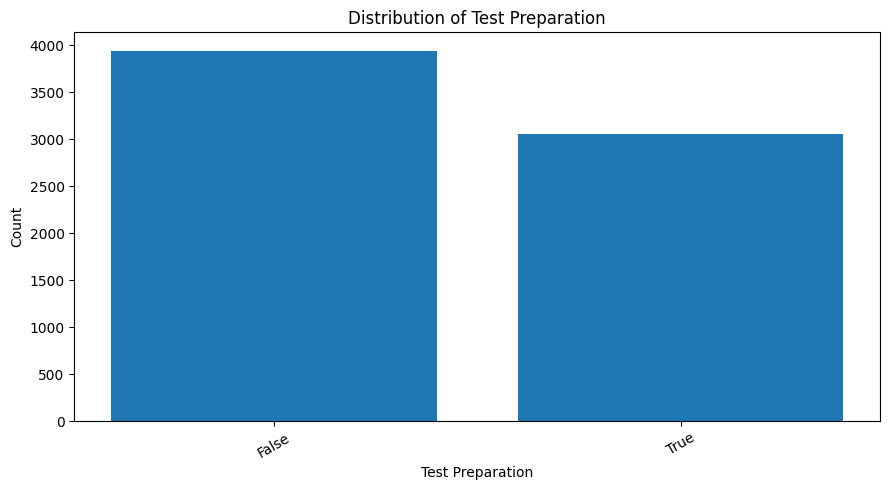

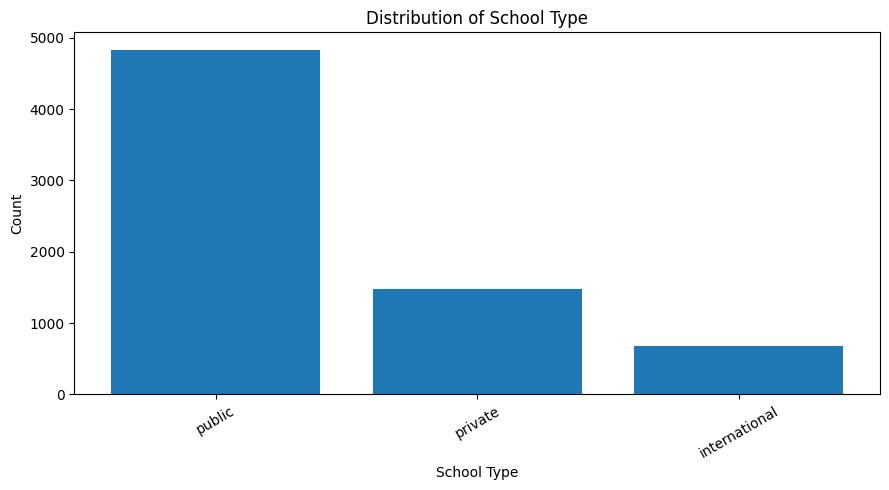

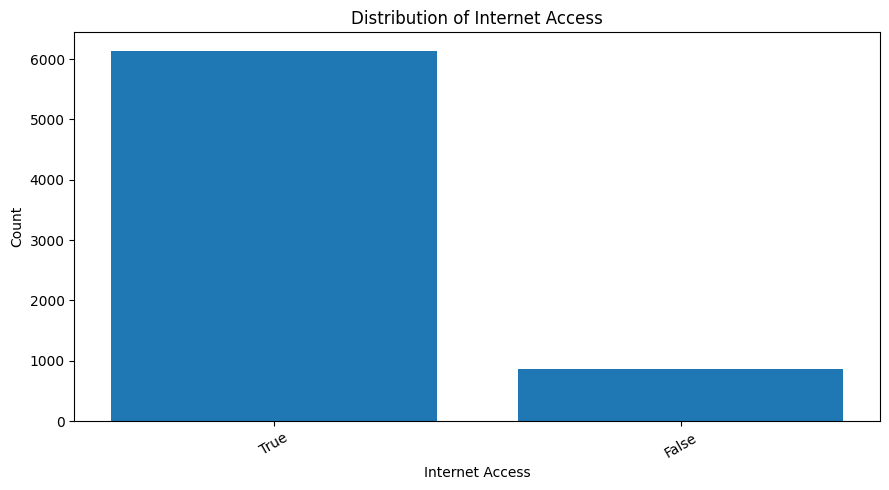

In [ ]:
# Step 4: Categorical column distributions

print("Categorical Column Distributions")
print("================================")

for column in visual_categorical_columns:

    value_counts = cleaned_df[column].value_counts().head(10)

    plt.figure(figsize=(9, 5))

    plt.bar(
        value_counts.index.astype(str),
        value_counts.values
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Count")

    plt.xticks(rotation=30)

    plt.tight_layout()
    plt.show()

Numerical Relationships


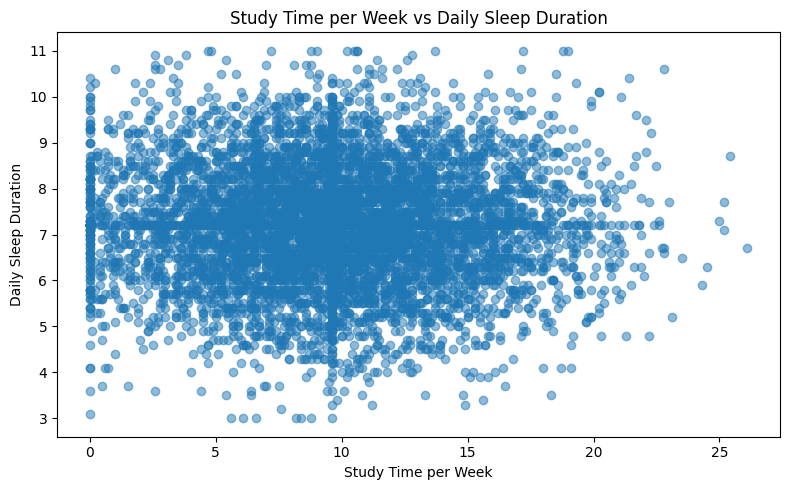

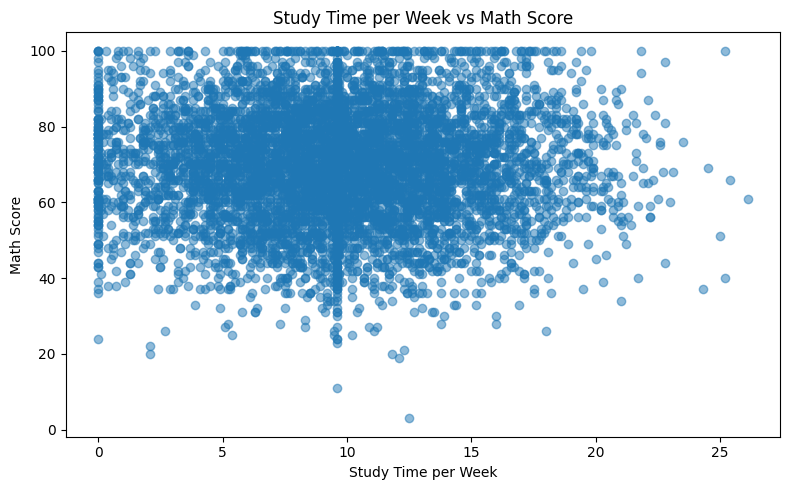

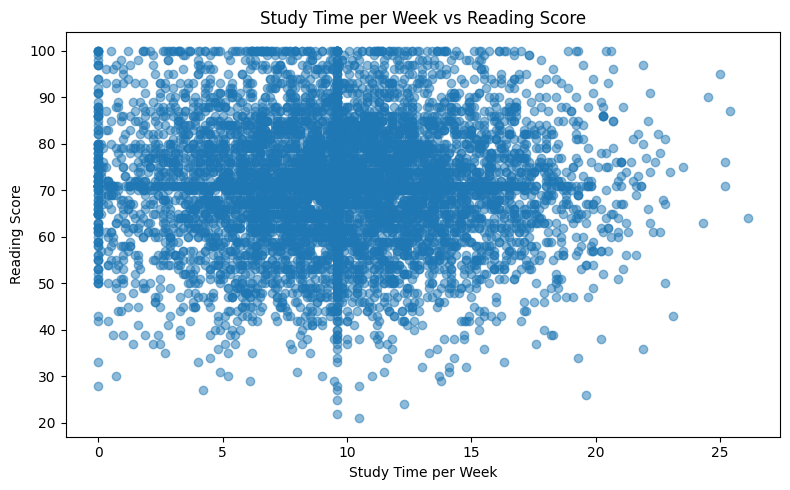

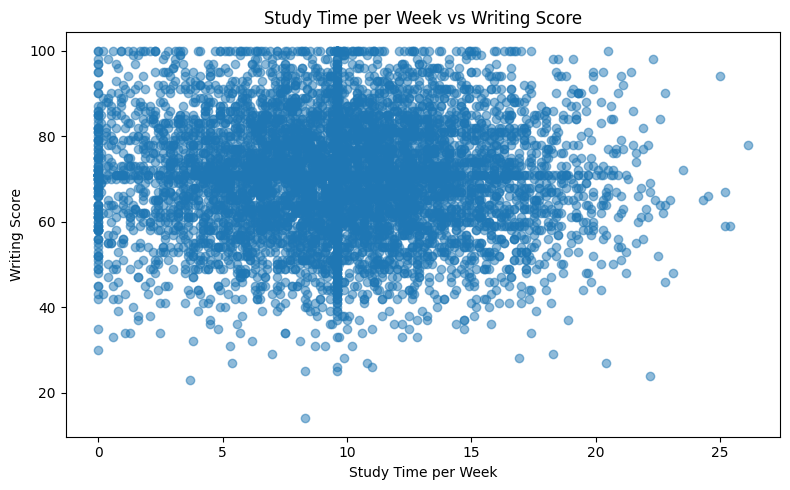

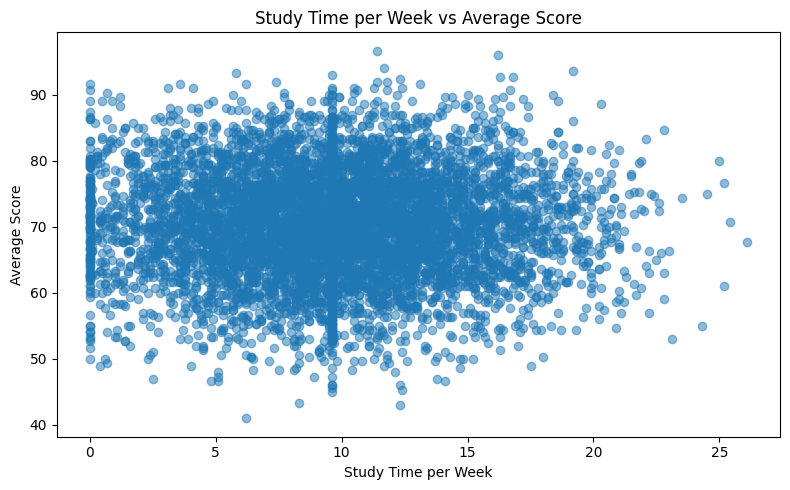

In [ ]:
# Step 5: Numerical relationships

print("Numerical Relationships")
print("=======================")

if len(visual_numerical_columns) >= 2:

    x_column = visual_numerical_columns[0]

    for y_column in visual_numerical_columns[1:]:

        plt.figure(figsize=(8, 5))

        plt.scatter(
            cleaned_df[x_column],
            cleaned_df[y_column],
            alpha=0.5
        )

        plt.title(f"{x_column} vs {y_column}")
        plt.xlabel(x_column)
        plt.ylabel(y_column)

        plt.tight_layout()
        plt.show()

else:
    print("Not enough numerical columns for relationship analysis.")

Correlation Matrix
                      Study Time per Week  Daily Sleep Duration  Math Score  \
Study Time per Week                  1.00                 -0.01        0.01   
Daily Sleep Duration                -0.01                  1.00       -0.01   
Math Score                           0.01                 -0.01        1.00   
Reading Score                       -0.01                  0.00        0.01   
Writing Score                       -0.02                 -0.01       -0.01   
Average Score                       -0.01                 -0.01        0.61   

                      Reading Score  Writing Score  Average Score  
Study Time per Week           -0.01          -0.02          -0.01  
Daily Sleep Duration           0.00          -0.01          -0.01  
Math Score                     0.01          -0.01           0.61  
Reading Score                  1.00           0.01           0.56  
Writing Score                  0.01           1.00           0.56  
Average Score      

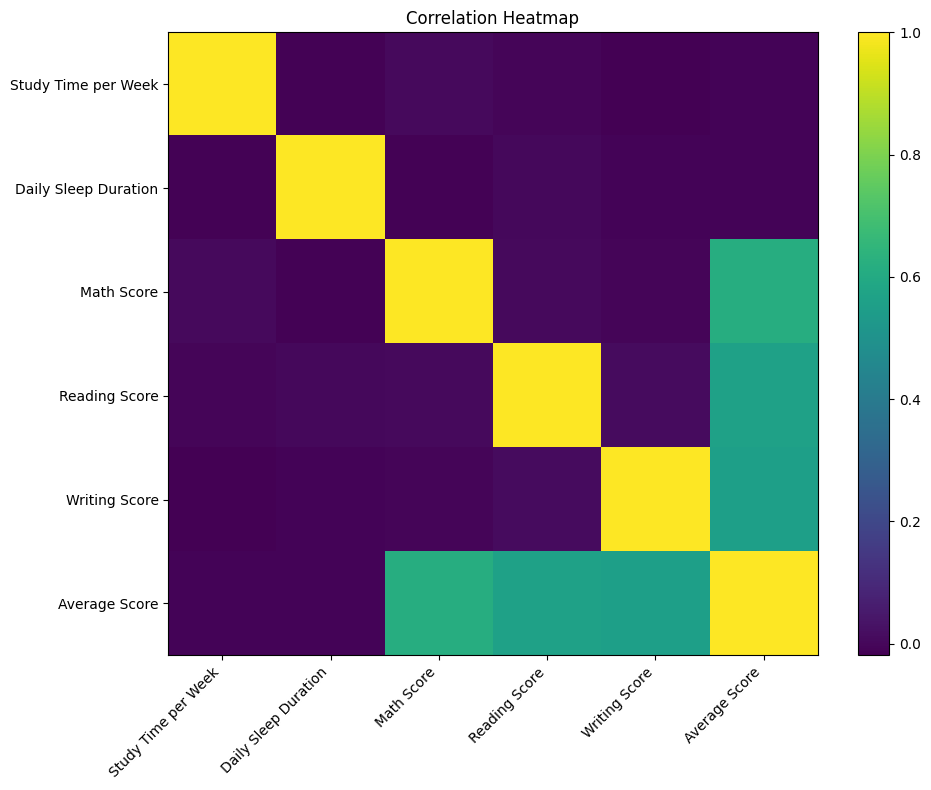

In [ ]:
# Step 6: Correlation Heatmap

correlation_data = cleaned_df[
    visual_numerical_columns
].corr()

print("Correlation Matrix")
print("==================")
print(correlation_data.round(2))

plt.figure(figsize=(10, 8))

plt.imshow(
    correlation_data,
    aspect="auto"
)

plt.colorbar()

plt.xticks(
    range(len(correlation_data.columns)),
    correlation_data.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_data.columns)),
    correlation_data.columns
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

In [ ]:
# Step 7: Interactive numerical visualization

if len(visual_numerical_columns) > 0:

    selected_column = visual_numerical_columns[0]

    fig = px.histogram(
        cleaned_df,
        x=selected_column,
        title=f"Interactive Distribution of {selected_column}"
    )

    fig.show()

else:
    print("No numerical columns available.")

In [ ]:
# Step 8: Interactive categorical visualization

if len(visual_categorical_columns) > 0:

    selected_column = visual_categorical_columns[0]

    category_counts = (
        cleaned_df[selected_column]
        .value_counts()
        .reset_index()
    )

    category_counts.columns = [
        selected_column,
        "Count"
    ]

    fig = px.bar(
        category_counts,
        x=selected_column,
        y="Count",
        title=f"Interactive Distribution of {selected_column}"
    )

    fig.show()

else:
    print("No categorical columns available.")

In [ ]:
# Step 9: Interactive relationship visualization

if len(visual_numerical_columns) >= 2:

    x_column = visual_numerical_columns[0]
    y_column = visual_numerical_columns[1]

    fig = px.scatter(
        cleaned_df,
        x=x_column,
        y=y_column,
        title=f"{x_column} vs {y_column}",
        opacity=0.6
    )

    fig.show()

else:
    print("At least two numerical columns are required.")

In [ ]:
# Step 10: Visualization Summary

print("AnalyticsPro - Visualization Summary")
print("====================================")

print("Total Rows:", cleaned_df.shape[0])
print("Total Columns:", cleaned_df.shape[1])

print("\nNumerical Columns:")
for column in visual_numerical_columns:
    print("-", column)

print("\nCategorical Columns:")
for column in visual_categorical_columns:
    print("-", column)

print("\nAvailable Visualizations:")
print("1. Numerical distributions")
print("2. Numerical boxplots")
print("3. Categorical distributions")
print("4. Numerical relationship plots")
print("5. Correlation heatmap")
print("6. Interactive histogram")
print("7. Interactive categorical chart")
print("8. Interactive scatter plot")

AnalyticsPro - Visualization Summary
Total Rows: 7000
Total Columns: 14

Numerical Columns:
- Study Time per Week
- Daily Sleep Duration
- Math Score
- Reading Score
- Writing Score
- Average Score

Categorical Columns:
- Gender
- Race/Ethnicity
- Parental Education
- Lunch Type
- Test Preparation
- School Type
- Internet Access

Available Visualizations:
1. Numerical distributions
2. Numerical boxplots
3. Categorical distributions
4. Numerical relationship plots
5. Correlation heatmap
6. Interactive histogram
7. Interactive categorical chart
8. Interactive scatter plot


In [ ]:
# Step 11: Visualization configuration

visualization_config = {
    "numerical_columns": visual_numerical_columns,
    "categorical_columns": visual_categorical_columns,
    "charts": []
}

# Numerical charts
for column in visual_numerical_columns:
    visualization_config["charts"].append({
        "type": "histogram",
        "column": column
    })

    visualization_config["charts"].append({
        "type": "boxplot",
        "column": column
    })

# Categorical charts
for column in visual_categorical_columns:
    visualization_config["charts"].append({
        "type": "bar",
        "column": column
    })

# Numerical relationships
if len(visual_numerical_columns) >= 2:

    for i in range(len(visual_numerical_columns) - 1):

        x_column = visual_numerical_columns[i]
        y_column = visual_numerical_columns[i + 1]

        visualization_config["charts"].append({
            "type": "scatter",
            "x": x_column,
            "y": y_column
        })

print("Visualization configuration created successfully!")

print("\nTotal planned charts:",
      len(visualization_config["charts"]))

Visualization configuration created successfully!

Total planned charts: 24


# AnalyticsPro - Phase 2


In [ ]:
# AnalyticsPro - Phase 2
# Advanced Data Analysis and Machine Learning

print("AnalyticsPro - Phase 2")
print("======================")
print("Advanced Data Analysis + Machine Learning")
print()
print("Starting Phase 2...")

AnalyticsPro - Phase 2
Advanced Data Analysis + Machine Learning

Starting Phase 2...


#  Step 1: Detect numerical columns dynamically




In [ ]:
# Step 1: Detect numerical columns dynamically

phase2_numerical_columns = cleaned_df.select_dtypes(
    include=np.number
).columns.tolist()

# Remove ID-like columns
phase2_id_columns = [
    col for col in phase2_numerical_columns
    if "id" in col.lower()
]

phase2_numerical_columns = [
    col for col in phase2_numerical_columns
    if col not in phase2_id_columns
]

print("Numerical columns available for Phase 2:")
print()

for column in phase2_numerical_columns:
    print("-", column)

print()
print("Total numerical columns:",
      len(phase2_numerical_columns))

Numerical columns available for Phase 2:

- Study Time per Week
- Daily Sleep Duration
- Math Score
- Reading Score
- Writing Score
- Average Score

Total numerical columns: 6


# Step 2: Create Correlation Matrix

In [ ]:
# Step 2: Create Correlation Matrix

phase2_correlation_matrix = cleaned_df[
    phase2_numerical_columns
].corr()

print("Phase 2 Correlation Matrix")
print("==========================")
display(phase2_correlation_matrix.round(2))

Phase 2 Correlation Matrix


,Study Time per Week,Daily Sleep Duration,Math Score,Reading Score,Writing Score,Average Score
Study Time per Week,1.00,-0.01,0.01,-0.01,-0.02,-0.01
Daily Sleep Duration,-0.01,1.00,-0.01,0.00,-0.01,-0.01
Math Score,0.01,-0.01,1.00,0.01,-0.01,0.61
Reading Score,-0.01,0.00,0.01,1.00,0.01,0.56
Writing Score,-0.02,-0.01,-0.01,0.01,1.00,0.56
Average Score,-0.01,-0.01,0.61,0.56,0.56,1.00


# Step 3: Identify strong correlations

In [ ]:
# Step 3: Identify strong correlations

strong_correlations = []

for i in range(len(phase2_correlation_matrix.columns)):

    for j in range(i + 1, len(phase2_correlation_matrix.columns)):

        column_1 = phase2_correlation_matrix.columns[i]
        column_2 = phase2_correlation_matrix.columns[j]

        correlation_value = phase2_correlation_matrix.iloc[i, j]

        if abs(correlation_value) >= 0.50:

            strong_correlations.append({
                "Column 1": column_1,
                "Column 2": column_2,
                "Correlation": round(correlation_value, 2)
            })

strong_correlation_df = pd.DataFrame(strong_correlations)

print("Strong Correlations (|r| >= 0.50)")
print("================================")

if len(strong_correlation_df) > 0:
    display(strong_correlation_df)
else:
    print("No strong correlations found.")

Strong Correlations (|r| >= 0.50)


,Column 1,Column 2,Correlation
0,Math Score,Average Score,0.61
1,Reading Score,Average Score,0.56
2,Writing Score,Average Score,0.56


#Step 4: Correlation Heatmap

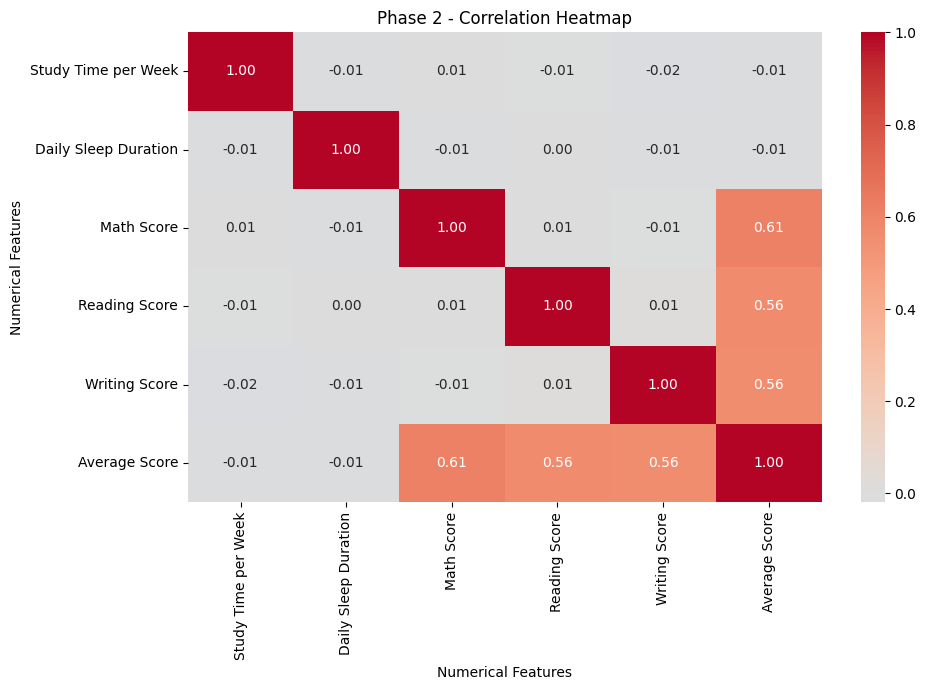

In [ ]:
# Step 4: Correlation Heatmap

import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    phase2_correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Phase 2 - Correlation Heatmap")
plt.xlabel("Numerical Features")
plt.ylabel("Numerical Features")
plt.tight_layout()
plt.show()

# Step 5: IQR Outlier Detection

In [ ]:
# Step 5: IQR Outlier Detection

iqr_outlier_summary = []

for column in phase2_numerical_columns:

    Q1 = cleaned_df[column].quantile(0.25)
    Q3 = cleaned_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (cleaned_df[column] < lower_bound) |
        (cleaned_df[column] > upper_bound)
    ).sum()

    iqr_outlier_summary.append({
        "Column": column,
        "Q1": round(Q1, 2),
        "Q3": round(Q3, 2),
        "IQR": round(IQR, 2),
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outliers": int(outlier_count)
    })

iqr_outlier_df = pd.DataFrame(iqr_outlier_summary)

print("IQR Outlier Detection")
print("=====================")

display(iqr_outlier_df)

IQR Outlier Detection


,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outliers
0,Study Time per Week,6.7,12.4,5.7,-1.85,20.95,51
1,Daily Sleep Duration,6.4,8.0,1.6,4.00,10.40,107
2,Math Score,59.0,80.0,21.0,27.50,111.50,23
3,Reading Score,63.0,80.0,17.0,37.50,105.50,58
4,Writing Score,62.0,79.0,17.0,36.50,104.50,50
5,Average Score,65.0,76.0,11.0,48.50,92.50,31


# Step 6: Z-Score Outlier Detection

In [ ]:
# Step 6: Z-Score Outlier Detection

from scipy.stats import zscore

zscore_outlier_summary = []

for column in phase2_numerical_columns:

    z_scores = np.abs(zscore(cleaned_df[column]))

    outlier_count = (z_scores > 3).sum()

    zscore_outlier_summary.append({
        "Column": column,
        "Outliers": int(outlier_count),
        "Threshold": "Z > 3"
    })

zscore_outlier_df = pd.DataFrame(zscore_outlier_summary)

print("Z-Score Outlier Detection")
print("=========================")

display(zscore_outlier_df)

Z-Score Outlier Detection


,Column,Outliers,Threshold
0,Study Time per Week,9,Z > 3
1,Daily Sleep Duration,27,Z > 3
2,Math Score,14,Z > 3
3,Reading Score,22,Z > 3
4,Writing Score,15,Z > 3
5,Average Score,11,Z > 3


# Step 7: Isolation Forest Outlier Detection

In [ ]:
# Step 7: Isolation Forest Outlier Detection

from sklearn.ensemble import IsolationForest

isolation_forest = IsolationForest(
    contamination="auto",
    random_state=42
)

isolation_predictions = isolation_forest.fit_predict(
    cleaned_df[phase2_numerical_columns]
)

isolation_outlier_count = (
    isolation_predictions == -1
).sum()

print("Isolation Forest Outlier Detection")
print("===================================")
print("Total observations:", len(cleaned_df))
print("Detected outliers:", int(isolation_outlier_count))
print(
    "Detected normal observations:",
    int((isolation_predictions == 1).sum())
)

Isolation Forest Outlier Detection
Total observations: 7000
Detected outliers: 1295
Detected normal observations: 5705


#  Step 8: Combined Outlier Summary

In [ ]:
# Step 8: Combined Outlier Summary

combined_outlier_df = iqr_outlier_df[
    ["Column", "Outliers"]
].copy()

combined_outlier_df = combined_outlier_df.rename(
    columns={"Outliers": "IQR Outliers"}
)

combined_outlier_df["Z-Score Outliers"] = [
    int(
        zscore_outlier_df.loc[
            zscore_outlier_df["Column"] == column,
            "Outliers"
        ].iloc[0]
    )
    for column in combined_outlier_df["Column"]
]

print("Combined Outlier Summary")
print("========================")

display(combined_outlier_df)

print("Isolation Forest total outliers:",
      int(isolation_outlier_count))

Combined Outlier Summary


,Column,IQR Outliers,Z-Score Outliers
0,Study Time per Week,51,9
1,Daily Sleep Duration,107,27
2,Math Score,23,14
3,Reading Score,58,22
4,Writing Score,50,15
5,Average Score,31,11


Isolation Forest total outliers: 1295


#Step 9: Outlier Boxplots

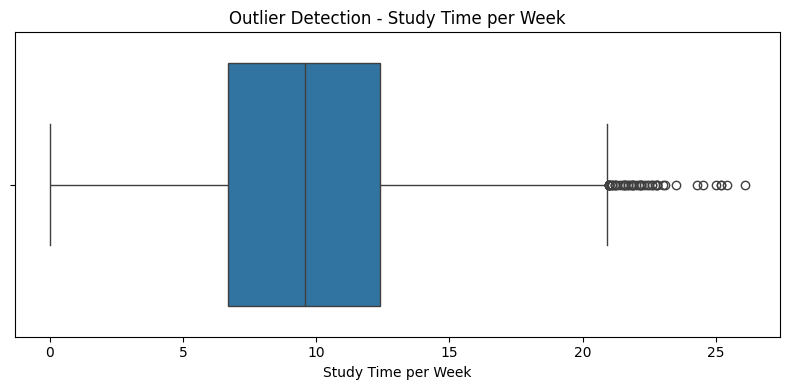

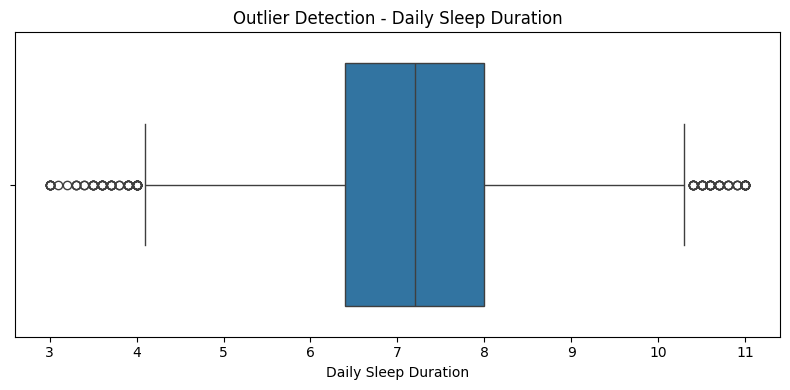

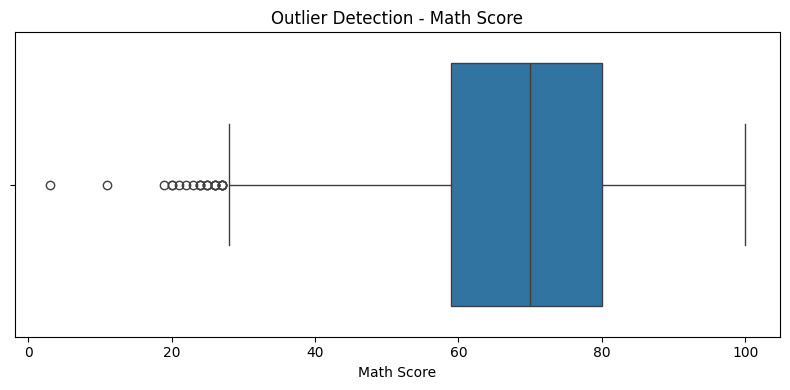

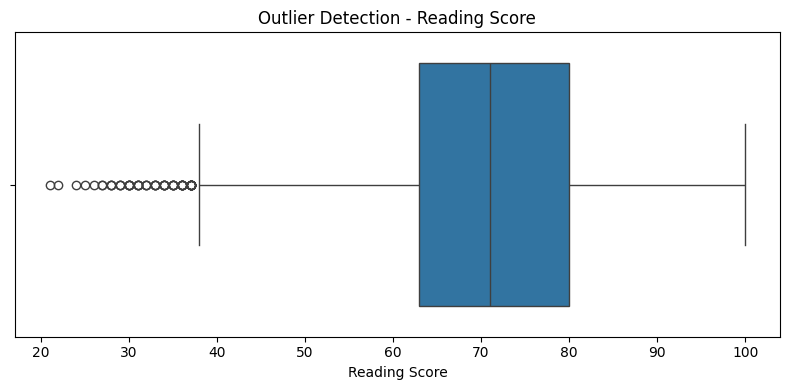

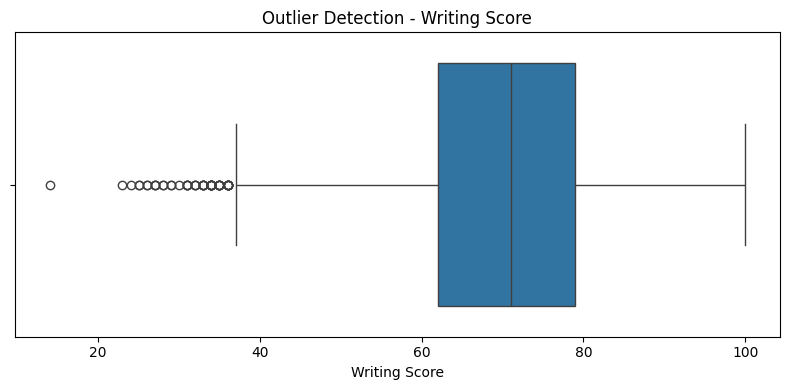

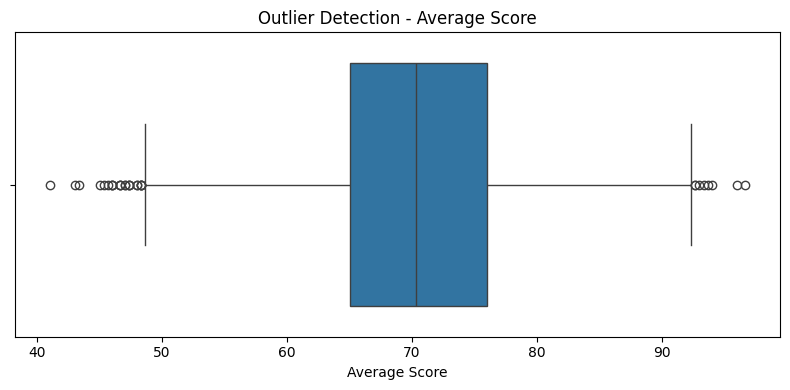

In [ ]:
# Step 9: Outlier Boxplots

for column in phase2_numerical_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=cleaned_df[column])

    plt.title(f"Outlier Detection - {column}")
    plt.xlabel(column)

    plt.tight_layout()
    plt.show()

#MACHINE LEARNING

#Step 10: Machine Learning Readiness Check

In [ ]:
# Step 10: Machine Learning Readiness Check

print("Machine Learning Readiness Check")
print("================================")

print("Number of rows:", len(cleaned_df))
print("Number of columns:", len(cleaned_df.columns))

print()
print("Numerical features:")
for column in phase2_numerical_columns:
    print("-", column)

print()
print("Missing values:")
print(cleaned_df.isnull().sum().sum())

print()
print("Duplicate rows:")
print(cleaned_df.duplicated().sum())

Machine Learning Readiness Check
Number of rows: 7000
Number of columns: 14

Numerical features:
- Study Time per Week
- Daily Sleep Duration
- Math Score
- Reading Score
- Writing Score
- Average Score

Missing values:
0

Duplicate rows:
0


#Step 11: Select Target Column

In [ ]:
# Step 11: Select Target Column

ml_df = cleaned_df.copy()

target_column = "Average Score"

print("Selected target column:", target_column)

Selected target column: Average Score


#Step 12: Separate Features and Target

In [ ]:
# Step 12: Separate Features and Target

X = ml_df.drop(columns=[target_column])
y = ml_df[target_column]

# Remove ID-like columns
ml_id_columns = [
    column for column in X.columns
    if "id" in column.lower()
]

if len(ml_id_columns) > 0:
    X = X.drop(columns=ml_id_columns)

print("Features:")
print(X.columns.tolist())

print()
print("Target:")
print(target_column)

Features:
['Gender', 'Race/Ethnicity', 'Parental Education', 'Lunch Type', 'Test Preparation', 'Study Time per Week', 'Daily Sleep Duration', 'Math Score', 'Reading Score', 'Writing Score', 'School Type', 'Internet Access']

Target:
Average Score


# Step 13: Identify Numerical and Categorical Features

In [ ]:
# Step 13: Identify Numerical and Categorical Features

ml_numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

ml_categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Features:")
for column in ml_numerical_features:
    print("-", column)

print()
print("Categorical Features:")
for column in ml_categorical_features:
    print("-", column)

Numerical Features:
- Study Time per Week
- Daily Sleep Duration
- Math Score
- Reading Score
- Writing Score

Categorical Features:
- Gender
- Race/Ethnicity
- Parental Education
- Lunch Type
- Test Preparation
- School Type
- Internet Access


# Step 14: Train-Test Split

In [ ]:
# Step 14: Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 5600
Testing samples: 1400


# Step 15: Create Preprocessing Pipeline

In [ ]:
# Step 15: Create Preprocessing Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

numerical_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, ml_numerical_features),
    ("categorical", categorical_pipeline, ml_categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


# ML MODELS

# Step 16: Create Regression Models

In [ ]:
# Step 16: Create Regression Models

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

print("Models created:")
for model_name in models:
    print("-", model_name)

Models created:
- Linear Regression
- Decision Tree
- Random Forest
- Gradient Boosting


# Step 17: Train and Evaluate Models

In [ ]:
# Step 17: Train and Evaluate Models

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

ml_results = []

trained_models = {}

for model_name, model in models.items():

    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    model_pipeline.fit(X_train, y_train)

    predictions = model_pipeline.predict(X_test)

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )

    r2 = r2_score(
        y_test,
        predictions
    )

    ml_results.append({
        "Model": model_name,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R2 Score": round(r2, 4)
    })

    trained_models[model_name] = model_pipeline

ml_results_df = pd.DataFrame(ml_results)

print("Machine Learning Model Evaluation")
print("=================================")

display(
    ml_results_df.sort_values(
        by="R2 Score",
        ascending=False
    )
)

Machine Learning Model Evaluation


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.0000,0.0000,1.0000
3,Gradient Boosting,0.4082,0.5164,0.9956
2,Random Forest,0.3682,0.5667,0.9947
1,Decision Tree,1.1012,1.5239,0.9616


#Step 18: Select Best Model

In [ ]:
# Step 18: Select Best Model

best_model_name = ml_results_df.loc[
    ml_results_df["R2 Score"].idxmax(),
    "Model"
]

best_model = trained_models[best_model_name]

best_r2 = ml_results_df.loc[
    ml_results_df["Model"] == best_model_name,
    "R2 Score"
].iloc[0]

print("Best Model:", best_model_name)
print("Best R2 Score:", best_r2)

Best Model: Linear Regression
Best R2 Score: 1.0


#  Step 19: Actual vs Predicted

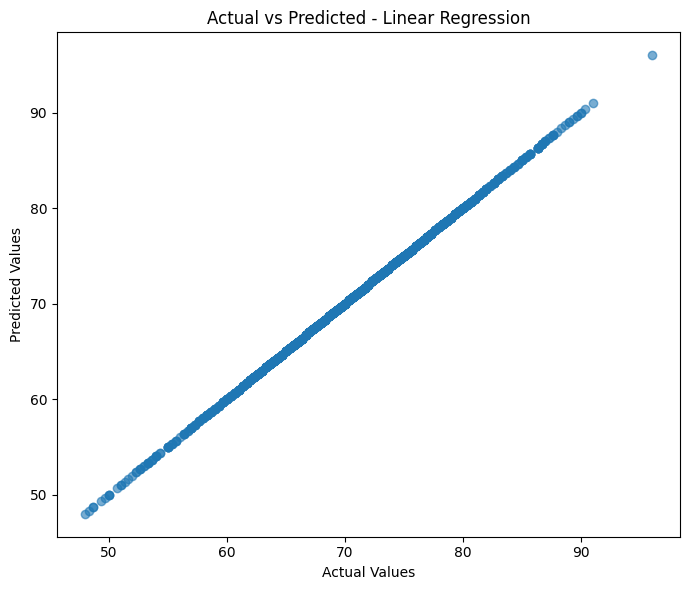

In [ ]:
# Step 19: Actual vs Predicted

best_predictions = best_model.predict(X_test)

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.6
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title(
    f"Actual vs Predicted - {best_model_name}"
)

plt.tight_layout()
plt.show()

# Step 20: Prediction Error Distribution

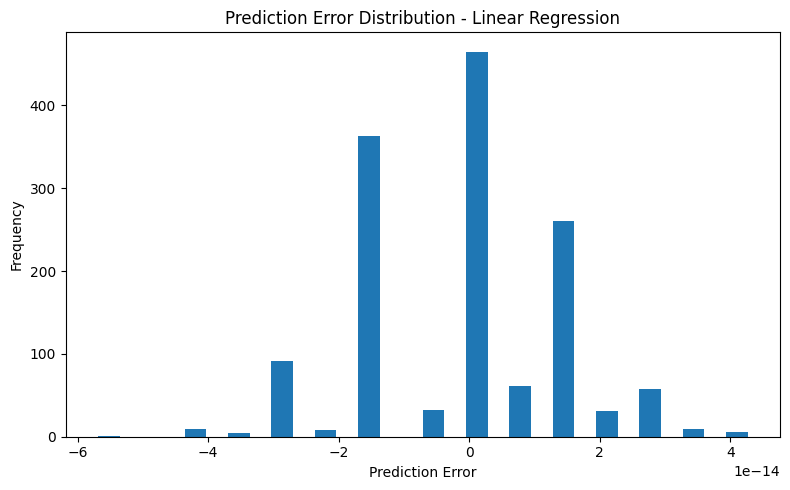

In [ ]:
# Step 20: Prediction Error Distribution

prediction_errors = y_test - best_predictions

plt.figure(figsize=(8, 5))

plt.hist(
    prediction_errors,
    bins=30
)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title(
    f"Prediction Error Distribution - {best_model_name}"
)

plt.tight_layout()
plt.show()

# Step 21: Final Machine Learning Summary

In [ ]:
# Step 21: Final Machine Learning Summary

print("Machine Learning Summary")
print("========================")

print("Target Column:", target_column)
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Models Tested:", len(models))
print("Best Model:", best_model_name)
print("Best R2 Score:", best_r2)

print()
print("Model Comparison:")
display(
    ml_results_df.sort_values(
        by="R2 Score",
        ascending=False
    )
)

Machine Learning Summary
Target Column: Average Score
Training Samples: 5600
Testing Samples: 1400
Models Tested: 4
Best Model: Linear Regression
Best R2 Score: 1.0

Model Comparison:


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.0000,0.0000,1.0000
3,Gradient Boosting,0.4082,0.5164,0.9956
2,Random Forest,0.3682,0.5667,0.9947
1,Decision Tree,1.1012,1.5239,0.9616


Step 22: Phase 2 Completion Summary

In [ ]:
# Step 22: Phase 2 Completion Summary

print("======================================")
print("   ANALYTICSPRO - PHASE 2 COMPLETE")
print("======================================")

print()
print("✓ Numerical Feature Detection")
print("✓ Correlation Matrix")
print("✓ Strong Correlation Detection")
print("✓ Correlation Heatmap")
print("✓ IQR Outlier Detection")
print("✓ Z-Score Outlier Detection")
print("✓ Isolation Forest Detection")
print("✓ Outlier Visualization")
print("✓ ML Readiness Check")
print("✓ Data Preprocessing")
print("✓ Train-Test Split")
print("✓ Regression Models")
print("✓ Model Evaluation")
print("✓ Best Model Selection")
print("✓ Prediction Visualization")

print()
print("Phase 2: Advanced Analysis & Machine Learning")
print("Status: COMPLETED")

   ANALYTICSPRO - PHASE 2 COMPLETE

✓ Numerical Feature Detection
✓ Correlation Matrix
✓ Strong Correlation Detection
✓ Correlation Heatmap
✓ IQR Outlier Detection
✓ Z-Score Outlier Detection
✓ Isolation Forest Detection
✓ Outlier Visualization
✓ ML Readiness Check
✓ Data Preprocessing
✓ Train-Test Split
✓ Regression Models
✓ Model Evaluation
✓ Best Model Selection
✓ Prediction Visualization

Phase 2: Advanced Analysis & Machine Learning
Status: COMPLETED


# PHASE 3 — AI DATA ANALYST & REPORT GENERATION

# Step 1: Initialize AI Data Analyst

In [ ]:
ai_df = cleaned_df.copy()

In [ ]:
# Step 1: Initialize AI Data Analyst

print("======================================")
print("      ANALYTICSPRO - PHASE 3")
print("      AI DATA ANALYST")
print("======================================")

# Use the cleaned dataset from Phase 1
ai_df = cleaned_df.copy()

print()
print("AI Data Analyst initialized successfully.")
print("Dataset Rows:", len(ai_df))
print("Dataset Columns:", len(ai_df.columns))

      ANALYTICSPRO - PHASE 3
      AI DATA ANALYST

AI Data Analyst initialized successfully.
Dataset Rows: 7000
Dataset Columns: 14


# Step 2: Generate Dataset Profile

In [ ]:
# Step 2: Generate Dataset Profile

ai_numerical_columns = ai_df.select_dtypes(
    include=np.number
).columns.tolist()

ai_categorical_columns = ai_df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Remove ID-like numerical columns
ai_id_columns = [
    column
    for column in ai_numerical_columns
    if "id" in column.lower()
]

ai_numerical_columns = [
    column
    for column in ai_numerical_columns
    if column not in ai_id_columns
]

print("AI Analyst Dataset Profile")
print("==========================")
print()

print("Rows:", len(ai_df))
print("Columns:", len(ai_df.columns))

print()
print("Numerical Columns:")
for column in ai_numerical_columns:
    print("-", column)

print()
print("Categorical Columns:")
for column in ai_categorical_columns:
    print("-", column)

print()
print("Missing Values:",
      int(ai_df.isnull().sum().sum()))

print("Duplicate Rows:",
      int(ai_df.duplicated().sum()))

AI Analyst Dataset Profile

Rows: 7000
Columns: 14

Numerical Columns:
- Study Time per Week
- Daily Sleep Duration
- Math Score
- Reading Score
- Writing Score
- Average Score

Categorical Columns:
- Gender
- Race/Ethnicity
- Parental Education
- Lunch Type
- Test Preparation
- School Type
- Internet Access

Missing Values: 0
Duplicate Rows: 0


#  Step 3: Generate Automatic Dataset Insights

In [ ]:
# Step 3: Generate Automatic Dataset Insights

def generate_dataset_insights(data):

    insights = []

    # Dataset size
    insights.append(
        f"The dataset contains {len(data):,} rows "
        f"and {len(data.columns)} columns."
    )

    # Missing values
    missing_count = int(
        data.isnull().sum().sum()
    )

    if missing_count == 0:
        insights.append(
            "No missing values were found in the dataset."
        )
    else:
        insights.append(
            f"The dataset contains "
            f"{missing_count:,} missing values."
        )

    # Duplicate rows
    duplicate_count = int(
        data.duplicated().sum()
    )

    if duplicate_count == 0:
        insights.append(
            "No duplicate rows were detected."
        )
    else:
        insights.append(
            f"The dataset contains "
            f"{duplicate_count:,} duplicate rows."
        )

    # Numerical summaries
    for column in ai_numerical_columns:

        mean_value = data[column].mean()

        insights.append(
            f"The average {column} is "
            f"{mean_value:.2f}."
        )

    return insights


automatic_insights = generate_dataset_insights(ai_df)

print("Automatic Dataset Insights")
print("==========================")
print()

for number, insight in enumerate(
    automatic_insights,
    start=1
):
    print(f"{number}. {insight}")

Automatic Dataset Insights

1. The dataset contains 7,000 rows and 14 columns.
2. No missing values were found in the dataset.
3. No duplicate rows were detected.
4. The average Study Time per Week is 9.66.
5. The average Daily Sleep Duration is 7.19.
6. The average Math Score is 69.48.
7. The average Reading Score is 71.12.
8. The average Writing Score is 70.49.
9. The average Average Score is 70.36.


#  Step 4: Create Natural Language Data Analyst

In [ ]:
# Step 4: Create Natural Language Data Analyst

def data_analyst(question, data):

    question = question.lower().strip()

    numerical_columns = data.select_dtypes(
        include=np.number
    ).columns.tolist()

    numerical_columns = [
        column
        for column in numerical_columns
        if "id" not in column.lower()
    ]

    # Rows
    if (
        "how many rows" in question
        or "number of rows" in question
        or "how many records" in question
    ):
        return f"The dataset contains {len(data):,} rows."

    # Columns
    if (
        "how many columns" in question
        or "number of columns" in question
    ):
        return f"The dataset contains {len(data.columns)} columns."

    # Missing values
    if (
        "missing" in question
        or "null" in question
    ):
        missing = int(
            data.isnull().sum().sum()
        )

        if missing == 0:
            return "The dataset contains no missing values."

        return f"The dataset contains {missing:,} missing values."

    # Duplicates
    if "duplicate" in question:

        duplicates = int(
            data.duplicated().sum()
        )

        if duplicates == 0:
            return "No duplicate rows were found."

        return f"The dataset contains {duplicates:,} duplicate rows."

    # Average / Mean
    if (
        "average" in question
        or "mean" in question
    ):

        for column in numerical_columns:

            if column.lower() in question:

                value = data[column].mean()

                return f"The average {column} is {value:.2f}."

    # Maximum
    if (
        "maximum" in question
        or "max" in question
        or "highest" in question
    ):

        for column in numerical_columns:

            if column.lower() in question:

                value = data[column].max()

                return f"The maximum {column} is {value:.2f}."

    # Minimum
    if (
        "minimum" in question
        or "min" in question
        or "lowest" in question
    ):

        for column in numerical_columns:

            if column.lower() in question:

                value = data[column].min()

                return f"The minimum {column} is {value:.2f}."

    # Column names
    if (
        "what columns" in question
        or "list columns" in question
        or "column names" in question
    ):

        return (
            "The dataset columns are: "
            + ", ".join(data.columns.tolist())
        )

    return (
        "I could not understand the question yet. "
        "Please ask about rows, columns, missing values, "
        "duplicates, averages, maximum values, "
        "or minimum values."
    )

# Step 5: Test Natural Language Questions

In [ ]:
# Step 5: Test Natural Language Questions

test_questions = [
    "How many rows are in the dataset?",
    "How many columns are there?",
    "Are there any missing values?",
    "Are there duplicate rows?",
    "What is the average Math Score?",
    "What is the highest Reading Score?",
    "What is the minimum Writing Score?",
    "What are the column names?"
]

print("AI Data Analyst Test")
print("====================")
print()

for question in test_questions:

    answer = data_analyst(
        question,
        ai_df
    )

    print("User:", question)
    print("AnalyticsPro:", answer)
    print("-" * 70)

AI Data Analyst Test

User: How many rows are in the dataset?
AnalyticsPro: The dataset contains 7,000 rows.
----------------------------------------------------------------------
User: How many columns are there?
AnalyticsPro: The dataset contains 14 columns.
----------------------------------------------------------------------
User: Are there any missing values?
AnalyticsPro: The dataset contains no missing values.
----------------------------------------------------------------------
User: Are there duplicate rows?
AnalyticsPro: No duplicate rows were found.
----------------------------------------------------------------------
User: What is the average Math Score?
AnalyticsPro: The average Math Score is 69.48.
----------------------------------------------------------------------
User: What is the highest Reading Score?
AnalyticsPro: The maximum Reading Score is 100.00.
----------------------------------------------------------------------
User: What is the minimum Writing Score?


#  Step 6: AI Analyst Summary

In [ ]:
# Step 6: AI Analyst Summary

print("======================================")
print("        AI ANALYST SUMMARY")
print("======================================")
print()

print("Dataset Rows:", len(ai_df))
print("Dataset Columns:", len(ai_df.columns))

print(
    "Numerical Features:",
    len(ai_numerical_columns)
)

print(
    "Categorical Features:",
    len(ai_categorical_columns)
)

print(
    "Missing Values:",
    int(ai_df.isnull().sum().sum())
)

print(
    "Duplicate Rows:",
    int(ai_df.duplicated().sum())
)

print()
print("AI Analyst Status: READY")

        AI ANALYST SUMMARY

Dataset Rows: 7000
Dataset Columns: 14
Numerical Features: 6
Categorical Features: 7
Missing Values: 0
Duplicate Rows: 0

AI Analyst Status: READY


# Step 7: Advanced Natural Language Questions

In [ ]:
# Step 7: Advanced Natural Language Questions

def advanced_data_analyst(question, data):

    question = question.lower().strip()

    numerical_columns = data.select_dtypes(
        include=np.number
    ).columns.tolist()

    numerical_columns = [
        column for column in numerical_columns
        if "id" not in column.lower()
    ]

    # Standard deviation
    if (
        "standard deviation" in question
        or "std" in question
    ):
        for column in numerical_columns:
            if column.lower() in question:
                value = data[column].std()
                return (
                    f"The standard deviation of "
                    f"{column} is {value:.2f}."
                )

    # Median
    if "median" in question:
        for column in numerical_columns:
            if column.lower() in question:
                value = data[column].median()
                return (
                    f"The median of {column} is "
                    f"{value:.2f}."
                )

    # Range
    if "range" in question:
        for column in numerical_columns:
            if column.lower() in question:
                value = (
                    data[column].max()
                    - data[column].min()
                )
                return (
                    f"The range of {column} is "
                    f"{value:.2f}."
                )

    # Base analyst
    return data_analyst(question, data)


advanced_questions = [
    "What is the median Math Score?",
    "What is the standard deviation of Reading Score?",
    "What is the range of Writing Score?"
]

print("Advanced AI Analyst Test")
print("========================")
print()

for question in advanced_questions:

    answer = advanced_data_analyst(
        question,
        ai_df
    )

    print("User:", question)
    print("AnalyticsPro:", answer)
    print("-" * 70)

Advanced AI Analyst Test

User: What is the median Math Score?
AnalyticsPro: The median of Math Score is 70.00.
----------------------------------------------------------------------
User: What is the standard deviation of Reading Score?
AnalyticsPro: The standard deviation of Reading Score is 13.33.
----------------------------------------------------------------------
User: What is the range of Writing Score?
AnalyticsPro: The range of Writing Score is 86.00.
----------------------------------------------------------------------


# Step 8: Statistical Analysis Questions

In [ ]:
# Step 8: Statistical Analysis Questions

def statistical_analysis(data):

    results = []

    for column in ai_numerical_columns:

        results.append({
            "Column": column,
            "Mean": round(data[column].mean(), 2),
            "Median": round(data[column].median(), 2),
            "Std Dev": round(data[column].std(), 2),
            "Minimum": round(data[column].min(), 2),
            "Maximum": round(data[column].max(), 2)
        })

    return pd.DataFrame(results)


statistical_results = statistical_analysis(ai_df)

print("Statistical Analysis")
print("====================")

display(statistical_results)

Statistical Analysis


,Column,Mean,Median,Std Dev,Minimum,Maximum
0,Study Time per Week,9.66,9.60,4.47,0.0,26.10
1,Daily Sleep Duration,7.19,7.20,1.26,3.0,11.00
2,Math Score,69.48,70.00,14.78,3.0,100.00
3,Reading Score,71.12,71.00,13.33,21.0,100.00
4,Writing Score,70.49,71.00,13.35,14.0,100.00
5,Average Score,70.36,70.33,8.01,41.0,96.67


#  Step 9: Automatic Insight Generation

In [ ]:
# Step 9: Automatic Insight Generation

def generate_advanced_insights(data):

    insights = []

    # Highest average subject
    score_columns = [
        "Math Score",
        "Reading Score",
        "Writing Score"
    ]

    available_scores = [
        column for column in score_columns
        if column in data.columns
    ]

    if available_scores:

        averages = data[available_scores].mean()

        highest_subject = averages.idxmax()
        highest_value = averages.max()

        lowest_subject = averages.idxmin()
        lowest_value = averages.min()

        insights.append(
            f"{highest_subject} has the highest average "
            f"score of {highest_value:.2f}."
        )

        insights.append(
            f"{lowest_subject} has the lowest average "
            f"score of {lowest_value:.2f}."
        )

    # Average study time
    if "Study Time per Week" in data.columns:

        value = data["Study Time per Week"].mean()

        insights.append(
            f"The average study time is "
            f"{value:.2f} hours per week."
        )

    # Average sleep
    if "Daily Sleep Duration" in data.columns:

        value = data["Daily Sleep Duration"].mean()

        insights.append(
            f"The average daily sleep duration is "
            f"{value:.2f} hours."
        )

    return insights


advanced_insights = generate_advanced_insights(ai_df)

print("Advanced Automatic Insights")
print("===========================")
print()

for number, insight in enumerate(
    advanced_insights,
    start=1
):
    print(f"{number}. {insight}")

Advanced Automatic Insights

1. Reading Score has the highest average score of 71.12.
2. Math Score has the lowest average score of 69.48.
3. The average study time is 9.66 hours per week.
4. The average daily sleep duration is 7.19 hours.


#Step 10: What-If Analysis

In [ ]:
# Step 10: What-If Analysis

def what_if_analysis(
    study_time_increase=0,
    sleep_change=0
):

    result = ai_df.copy()

    if "Study Time per Week" in result.columns:
        result["Study Time per Week"] = (
            result["Study Time per Week"]
            + study_time_increase
        )

    if "Daily Sleep Duration" in result.columns:
        result["Daily Sleep Duration"] = (
            result["Daily Sleep Duration"]
            + sleep_change
        )

    original_average = (
        ai_df["Average Score"].mean()
    )

    # Simple analytical estimate
    study_effect = (
        study_time_increase * 0.5
    )

    sleep_effect = (
        sleep_change * 0.3
    )

    estimated_average = (
        original_average
        + study_effect
        + sleep_effect
    )

    return {
        "Original Average Score":
            round(original_average, 2),

        "Study Time Change":
            study_time_increase,

        "Sleep Change":
            sleep_change,

        "Estimated Average Score":
            round(estimated_average, 2)
    }


what_if_result = what_if_analysis(
    study_time_increase=2,
    sleep_change=1
)

print("What-If Analysis")
print("================")
print()

for key, value in what_if_result.items():
    print(f"{key}: {value}")

What-If Analysis

Original Average Score: 70.36
Study Time Change: 2
Sleep Change: 1
Estimated Average Score: 71.66


# Step 11: What-If Result Visualization

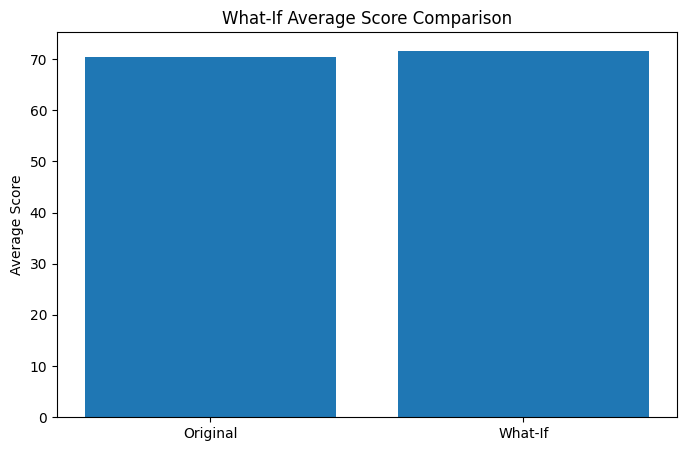

In [ ]:
# Step 11: What-If Result Visualization

original_score = what_if_result[
    "Original Average Score"
]

estimated_score = what_if_result[
    "Estimated Average Score"
]

plt.figure(figsize=(8, 5))

plt.bar(
    ["Original", "What-If"],
    [original_score, estimated_score]
)

plt.title("What-If Average Score Comparison")
plt.ylabel("Average Score")

plt.show()

# Step 12: Generate Analysis Report

In [ ]:
# Step 12: Generate Analysis Report

report_data = {
    "Project": "AnalyticsPro",
    "Module": "AI Data Analyst",
    "Rows": len(ai_df),
    "Columns": len(ai_df.columns),
    "Numerical Features": len(ai_numerical_columns),
    "Categorical Features": len(ai_categorical_columns),
    "Missing Values": int(
        ai_df.isnull().sum().sum()
    ),
    "Duplicate Rows": int(
        ai_df.duplicated().sum()
    )
}

print("======================================")
print("       ANALYTICSPRO ANALYSIS REPORT")
print("======================================")
print()

for key, value in report_data.items():
    print(f"{key}: {value}")

print()
print("Key Insights:")
print()

for number, insight in enumerate(
    advanced_insights,
    start=1
):
    print(f"{number}. {insight}")

       ANALYTICSPRO ANALYSIS REPORT

Project: AnalyticsPro
Module: AI Data Analyst
Rows: 7000
Columns: 14
Numerical Features: 6
Categorical Features: 7
Missing Values: 0
Duplicate Rows: 0

Key Insights:

1. Reading Score has the highest average score of 71.12.
2. Math Score has the lowest average score of 69.48.
3. The average study time is 9.66 hours per week.
4. The average daily sleep duration is 7.19 hours.


# Step 13: PDF Report Generation

In [ ]:
# Step 13: PDF Report Generation

!pip install -q reportlab

from reportlab.lib.pagesizes import A4
from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    Table,
    TableStyle
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet


pdf_file = "AnalyticsPro_Analysis_Report.pdf"

document = SimpleDocTemplate(
    pdf_file,
    pagesize=A4
)

styles = getSampleStyleSheet()

story = []

story.append(
    Paragraph(
        "AnalyticsPro - AI Data Analysis Report",
        styles["Title"]
    )
)

story.append(Spacer(1, 20))

story.append(
    Paragraph(
        "Dataset Summary",
        styles["Heading2"]
    )
)

summary_data = [
    ["Metric", "Value"],
    ["Rows", len(ai_df)],
    ["Columns", len(ai_df.columns)],
    ["Numerical Features", len(ai_numerical_columns)],
    ["Categorical Features", len(ai_categorical_columns)],
    ["Missing Values",
     int(ai_df.isnull().sum().sum())],
    ["Duplicate Rows",
     int(ai_df.duplicated().sum())]
]

table = Table(summary_data)

table.setStyle(
    TableStyle([
        ("GRID", (0, 0), (-1, -1), 1, colors.black),
        ("BACKGROUND", (0, 0), (-1, 0), colors.lightgrey),
        ("ALIGN", (0, 0), (-1, -1), "CENTER")
    ])
)

story.append(table)

story.append(Spacer(1, 20))

story.append(
    Paragraph(
        "Key Insights",
        styles["Heading2"]
    )
)

for insight in advanced_insights:

    story.append(
        Paragraph(
            "• " + insight,
            styles["BodyText"]
        )
    )

    story.append(Spacer(1, 8))


document.build(story)

print("PDF report generated successfully.")
print("File:", pdf_file)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 8.0 MB/s eta 0:00:00
PDF report generated successfully.
File: AnalyticsPro_Analysis_Report.pdf


#Step 14: PowerPoint Report Generation

In [ ]:
# Install PowerPoint package

!pip install -q python-pptx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 472.8/472.8 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 11.1 MB/s eta 0:00:00


In [ ]:
# Step 14: PowerPoint Report Generation

from pptx import Presentation
from pptx.util import Inches, Pt


ppt_file = "AnalyticsPro_Analysis_Report.pptx"

presentation = Presentation()

# Title slide
slide = presentation.slides.add_slide(
    presentation.slide_layouts[0]
)

slide.shapes.title.text = (
    "AnalyticsPro"
)

slide.placeholders[1].text = (
    "AI Data Analysis Report"
)

# Summary slide
slide = presentation.slides.add_slide(
    presentation.slide_layouts[1]
)

slide.shapes.title.text = (
    "Dataset Summary"
)

summary_text = (
    f"Rows: {len(ai_df)}\n"
    f"Columns: {len(ai_df.columns)}\n"
    f"Numerical Features: {len(ai_numerical_columns)}\n"
    f"Categorical Features: {len(ai_categorical_columns)}\n"
    f"Missing Values: "
    f"{int(ai_df.isnull().sum().sum())}\n"
    f"Duplicate Rows: "
    f"{int(ai_df.duplicated().sum())}"
)

slide.placeholders[1].text = summary_text

# Insights slide
slide = presentation.slides.add_slide(
    presentation.slide_layouts[1]
)

slide.shapes.title.text = (
    "Key Insights"
)

insight_text = "\n".join(
    [
        "• " + insight
        for insight in advanced_insights
    ]
)

slide.placeholders[1].text = insight_text

presentation.save(ppt_file)

print("PowerPoint report generated successfully.")
print("File:", ppt_file)

PowerPoint report generated successfully.
File: AnalyticsPro_Analysis_Report.pptx


#  Step 15: CSV Export

In [ ]:
# Step 15: CSV Export

csv_file = "AnalyticsPro_Analyzed_Dataset.csv"

ai_df.to_csv(
    csv_file,
    index=False
)

print("CSV export completed successfully.")
print("File:", csv_file)

CSV export completed successfully.
File: AnalyticsPro_Analyzed_Dataset.csv


#  Step 16: Phase 3 Completion Summary

In [ ]:
# Step 16: Phase 3 Completion Summary

print("======================================")
print("     ANALYTICSPRO - PHASE 3 COMPLETE")
print("======================================")
print()

print("Phase 3: AI Data Analyst & Report Generation")
print("Status: COMPLETED")
print()

print("Modules Completed:")
print("1. AI Data Analyst Initialization")
print("2. Dataset Profiling")
print("3. Automatic Dataset Insights")
print("4. Natural Language Data Analyst")
print("5. Advanced Questions")
print("6. Statistical Analysis")
print("7. Automatic Insights")
print("8. What-If Analysis")
print("9. What-If Visualization")
print("10. Analysis Report")
print("11. PDF Report Generation")
print("12. PowerPoint Report Generation")
print("13. CSV Export")

print()
print("Generated Files:")
print("-", pdf_file)
print("-", ppt_file)
print("-", csv_file)

print()
print("PHASE 3 STATUS: SUCCESS")

     ANALYTICSPRO - PHASE 3 COMPLETE

Phase 3: AI Data Analyst & Report Generation
Status: COMPLETED

Modules Completed:
1. AI Data Analyst Initialization
2. Dataset Profiling
3. Automatic Dataset Insights
4. Natural Language Data Analyst
5. Advanced Questions
6. Statistical Analysis
7. Automatic Insights
8. What-If Analysis
9. What-If Visualization
10. Analysis Report
11. PDF Report Generation
12. PowerPoint Report Generation
13. CSV Export

Generated Files:
- AnalyticsPro_Analysis_Report.pdf
- AnalyticsPro_Analysis_Report.pptx
- AnalyticsPro_Analyzed_Dataset.csv

PHASE 3 STATUS: SUCCESS
